# NLP Assignment 1 — N-gram Language Models for Amharic

**Corpus:** GPAC — General-Purpose Amharic Corpus (Gereme, Zhu, Ayall & Alemu, *Information* 2021, 12(1), 20,
[doi:10.3390/info12010020](https://doi.org/10.3390/info12010020)).

| Task | Weight | Section |
|---|---|---|
| 1 — N-gram language model (statistics, n-grams, probabilities, stop words, word clouds, sentence probability, generation) | 6% | [Task 1](#task1) |
| 2 — Intrinsic evaluation (perplexity) for n = 1–4 | 3% | [Task 2](#task2) |
| 3 — Extrinsic evaluation (three downstream tasks) | 5% | [Task 3](#task3) |
| 4 — Amharic predictive text / next-word suggestion system | 6% | [Task 4](#task4) |

**How the code is organised.** The heavy lifting lives in the small package `amharic_lm/` next to this notebook
(preprocessing, a numpy-based n-gram engine, evaluation, plotting); this notebook calls it and shows every
result. A Python `dict` of tuples cannot hold the ~120 million distinct n-grams of an 80-million-token corpus in
12–16 GB of RAM, so each n-gram order is stored as **sorted integer arrays** (contexts packed into 64-bit keys,
21 bits per word) and every lookup is a binary search. Building all four orders over the whole corpus takes about
a minute on a laptop, and evaluating millions of test n-grams takes about a second.

**Running it.** `pip install -r requirements.txt`, then run all cells. The corpus is downloaded from Google
Drive on the first run; the encoded corpus and the models are cached under `artifacts/` (built automatically,
or ahead of time with `python scripts/build_artifacts.py`). Peak memory is about 6 GB.

In [1]:
import sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))

from amharic_lm import paths, pipeline, preprocess, viz
from amharic_lm import analysis as an, evaluation as ev
from amharic_lm.corpus import BOS, EOS, UNK, sentence_hashes
from amharic_lm.ngram import NGramTable
from amharic_lm.stopwords import STOPWORDS, stopword_mask
from amharic_lm.predictor import NextWordPredictor

viz.apply_style()
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
fmt = lambda x: (f"{x:,.0f}" if abs(x) >= 1e4 else f"{x:,.4g}" if abs(x) >= 1e-4 or x == 0 else f"{x:.3e}")
pd.set_option("display.float_format", fmt)
T0 = time.time()

<a id="task1"></a>
# Task 1 — N-gram language model

## 1.1 Corpus statistics and preprocessing

### Raw corpus

In [2]:
corpus_path = pipeline.download_corpus()
raw_text = corpus_path.read_text(encoding="utf-8")
print(f"file size : {corpus_path.stat().st_size / 1e9:.2f} GB")
print(f"characters: {len(raw_text):,}")
print(f"newlines  : {raw_text.count(chr(10)):,}   (the whole corpus is one line)")
print(f"spaces    : {raw_text.count(' '):,}  -> about {raw_text.count(' ') / 1e6:.0f}M whitespace-separated chunks\n")
print(raw_text[:700])

file size : 1.06 GB
characters: 424,397,739
newlines  : 0   (the whole corpus is one line)


spaces    : 99,094,951  -> about 99M whitespace-separated chunks

    ምን መሰላችሁ? (አንባቢያን) ኢትዮጵያ በተደጋጋሚ ጥሪው ደርሷት ልትታደመው ያልቻለችው የአለም የእግር ኳስ ዋ ለ19ኛ ጊዜ በደቡብ አፍሪካ ሲጠጣ፣ በሩቅ እያየች አንጀቷ ባረረ ልክ በአመቱ በለስ ቀናትና ሌላ ዋ ልትታደም ሁለት ልጆቿን ወደ ደቡብ አፍሪካ ላከች፡፡6ኛው ቢግ ብራዘርስ አፍሪካ አብሮ የመኖር ውድድር በደቡብ አፍሪካ ተካሂዷል፡፡ ከተለያዩ 14 የአፍሪካ አገራት የተውጣጡ 26 ያህል ተሳታፊዎች የተካፈሉበት ይህ ውድድር፣ ግለሰቦች በፈታኝ ሁኔታ ውስጥ በማለፍ ብቃታቸውን የሚያስመሰክሩበት መሆኑን ሰምተናል፡፡ የሚገጥሟቸውን የተለያዩ ፈተናዎች በትእግስትና በጥበብ ማለፍ፣ ከሌሎች ጋር ተስማምቶ መዝለቅ፣ ችግሮችን በብልጠት መፍታት ወዘተ     በየጊዜው ከሚደረገው ቅነሳ ተርፈው ለ91 ቀናት ያህል በውድድሩ መቆየት የቻሉ ሁለት ተወዳዳሪዎች እያንዳንዳቸው 200 ሺህ ዶላር እንደሚሸለሙም ሲናገር ነበር፡፡ በዘንድሮው ውድድር አገራችን ዳኒ እና ሃኒ የተባሉ ሁለት ወጣቶችን ብታሰልፍም ዳኒ ቀደም ብሎ የቅነሳው ሰለባ ሲሆን ሃኒም በቅርቡ ከውድድር ውጭ ሆናለች፡፡ይህቺን የአገሪቱ ብቸኛ ተስፋ ወደ አሸናፊነት ለማሸጋገር የህዝብ የድጋፍ ድም ወሳኝ መሆኑን የተገነዘበው ወዳጄ ነው እንግዲህ         


In [3]:
cat_df, sym_df, n_distinct = an.char_stats(raw_text)
print(f"{n_distinct} distinct characters")
display(cat_df)
display(sym_df.head(14))

368 distinct characters


,category,characters,%
0,Ethiopic letter,310703030,73.21
1,whitespace,99094951,23.35
2,Ethiopic punctuation,8515491,2.006
3,ASCII digit,3892932,0.9173
4,other symbol,2059690,0.4853
5,Ethiopic numeral,131645,0.03102


,symbol,code point,name,count
0,።,U+1362,Ethiopic Full Stop,3113238
1,፡,U+1361,Ethiopic Wordspace,2811013
2,፣,U+1363,Ethiopic Comma,1688346
3,፤,U+1364,Ethiopic Semicolon,819215
4,?,U+003F,Question Mark,488345
5,),U+0029,Right Parenthesis,404657
6,(,U+0028,Left Parenthesis,397904
7,/,U+002F,Solidus,371308
8,!,U+0021,Exclamation Mark,300736
9,:,U+003A,Colon,87540


**What the raw data tells us.** The file has already been cleaned by its creators: it contains only Ethiopic
script, spaces, digits and about a dozen punctuation marks (no Latin letters, no HTML, no newlines). Sentence ends
are written as `።`, as two Ethiopic word-spaces `፡፡`, or as `?` and `!`. Commas and semicolons (`፣ ፤`) and
brackets occur inside sentences, and `/` marks abbreviations (`ት/ቤት` *school*, `ዓ/ም` *E.C.*, `ጠ/ሚ` *P.M.*).

### Preprocessing pipeline

| Step | What is done | Why |
|---|---|---|
| 0. Repair | the dump deleted `.` `,` `-`, so `ዓ.ም` became `ዓ ም`, `እ.ኤ.አ` became `እ ኤ አ` and `8.4` became `8 4`; runs of single letters are re-joined as slash abbreviations (`ዓ/ም`, `እ/ኤ/አ`, `ኪ/ሜ`) and runs of digits as one number | otherwise the most frequent "n-grams" are fragments such as `ዓ ም` and `<NUM> <NUM>` |
| 1. Sentence splitting | split on `።`, `፡፡`, `::`, `?`, `!`, `፧`, `፨`; empty sentences dropped | sentences are the unit of an n-gram LM (padding with `<s>`, `</s>`) |
| 2. Tokenisation | a token is a run of Ethiopic letters/digits, optionally joined by `/` (keeps `ት/ቤት` whole); every other symbol is a separator | Amharic words are space-delimited; punctuation carries no lexical content here |
| 3. Homophone normalisation | `ሐ ኀ → ሀ`, `ሠ → ሰ`, `ዐ → አ`, `ፀ → ጸ` (all 7 vowel orders), `ሃ → ሀ`, `ኣ ዓ → አ`, `ዉ → ው` | these letters are pronounced identically in modern Amharic and spelled inconsistently (ሀገር / ሃገር / ሐገር); merging them reduces sparsity |
| 4. Number normalisation | digit runs (Arabic or Ethiopic numerals) → `<NUM>`: `2010 → <NUM>`, `ለ19ኛ → ለ<NUM>ኛ` | thousands of distinct numbers collapse into one predictable class |
| 5. De-duplication | repeated sentences with ≥ 5 tokens are removed (the first copy is kept) | the corpus repeats articles and boilerplate; duplicates inflate counts and leak between train and test |

Each word id keeps its *most frequent original spelling* for display, so tables show `ዓመት` rather than the
normalised `አመት`.

In [4]:
demo = "በ8 4 ቢሊዮን ዶላር ሐምሌ 28 2003 ዓ ም ተፈረመ፡፡ እ ኤ አ ከ2004 2007 ድረስ"
print("repair    :", demo, "->", preprocess.repair(demo), "\n")
for s in preprocess.split_sentences(raw_text[:700])[:4]:
    print("sentence :", s)
    print("tokens   :", preprocess.tokenize(s, normalize=False))
    print("normalised:", preprocess.tokenize(s), "\n")

examples = ["ዓመት", "ሀገር", "ሃገር", "ሐገር", "ኀይል", "ሥራ", "ፀሐይ", "ጸሀይ", "ነዉ", "በ2010", "ለ19ኛ", "ት/ቤት", "፳፻"]
display(pd.DataFrame({"raw token": examples,
                      "normalised": [preprocess.normalize_token(w) for w in examples]}).T)

repair    : በ8 4 ቢሊዮን ዶላር ሐምሌ 28 2003 ዓ ም ተፈረመ፡፡ እ ኤ አ ከ2004 2007 ድረስ -> በ84 ቢሊዮን ዶላር ሐምሌ 282003 ዓ/ም ተፈረመ፡፡ እ/ኤ/አ ከ20042007 ድረስ 

sentence : ምን መሰላችሁ
tokens   : ['ምን', 'መሰላችሁ']
normalised: ['ምን', 'መሰላችሁ'] 

sentence : (አንባቢያን) ኢትዮጵያ በተደጋጋሚ ጥሪው ደርሷት ልትታደመው ያልቻለችው የአለም የእግር ኳስ ዋ ለ19ኛ ጊዜ በደቡብ አፍሪካ ሲጠጣ፣ በሩቅ እያየች አንጀቷ ባረረ ልክ በአመቱ በለስ ቀናትና ሌላ ዋ ልትታደም ሁለት ልጆቿን ወደ ደቡብ አፍሪካ ላከች
tokens   : ['አንባቢያን', 'ኢትዮጵያ', 'በተደጋጋሚ', 'ጥሪው', 'ደርሷት', 'ልትታደመው', 'ያልቻለችው', 'የአለም', 'የእግር', 'ኳስ', 'ዋ', 'ለ19ኛ', 'ጊዜ', 'በደቡብ', 'አፍሪካ', 'ሲጠጣ', 'በሩቅ', 'እያየች', 'አንጀቷ', 'ባረረ', 'ልክ', 'በአመቱ', 'በለስ', 'ቀናትና', 'ሌላ', 'ዋ', 'ልትታደም', 'ሁለት', 'ልጆቿን', 'ወደ', 'ደቡብ', 'አፍሪካ', 'ላከች']
normalised: ['አንባቢያን', 'ኢትዮጵያ', 'በተደጋጋሚ', 'ጥሪው', 'ደርሷት', 'ልትታደመው', 'ያልቻለችው', 'የአለም', 'የእግር', 'ኳስ', 'ዋ', 'ለ<NUM>ኛ', 'ጊዜ', 'በደቡብ', 'አፍሪካ', 'ሲጠጣ', 'በሩቅ', 'እያየች', 'አንጀቷ', 'ባረረ', 'ልክ', 'በአመቱ', 'በለስ', 'ቀናትና', 'ሌላ', 'ዋ', 'ልትታደም', 'ሁለት', 'ልጆቿን', 'ወደ', 'ደቡብ', 'አፍሪካ', 'ላከች'] 

sentence : 6ኛው ቢግ ብራዘርስ አፍሪካ አብሮ የመኖር ውድድር በደቡብ አፍሪካ ተካሂዷል
tokens   : ['6ኛው', 'ቢግ', 'ብራዘርስ', 'አፍሪካ

,0,1,2,3,4,5,6,7,8,9,10,11,12
raw token,ዓመት,ሀገር,ሃገር,ሐገር,ኀይል,ሥራ,ፀሐይ,ጸሀይ,ነዉ,በ2010,ለ19ኛ,ት/ቤት,፳፻
normalised,አመት,ሀገር,ሀገር,ሀገር,ሀይል,ስራ,ጸሀይ,ጸሀይ,ነው,በ<NUM>,ለ<NUM>ኛ,ት/ቤት,<NUM>


In [5]:
raw = pipeline.raw_corpus()       # steps 1-4 (cached after the first run, ~20 s)
clean = pipeline.clean_corpus()   # + step 5
del raw_text

info = clean.info
funnel = pd.DataFrame({"value": [
    info["raw_chars"], info["raw_terminators"], info["raw_types"], info["normalised_types"],
    raw.n_sentences, raw.n_tokens, info["duplicate_sentences_all"],
    info["removed_sentences"], info["removed_tokens"], clean.n_sentences, clean.n_tokens]},
    index=["raw characters", "sentence terminators found", "token types before normalisation",
           "token types after normalisation", "non-empty sentences", "tokens",
           "sentences that repeat an earlier one", "duplicate sentences removed (>= 5 tokens)",
           "tokens removed by de-duplication", "sentences in clean corpus", "tokens in clean corpus"])
funnel["value"] = funnel["value"].map("{:,}".format)
print(f"Normalisation merged {info['raw_types'] - info['normalised_types']:,} spelling variants "
      f"({1 - info['normalised_types'] / info['raw_types']:.1%} of the raw types).")
funnel

loading cached encoded corpus from /Users/ashenafi/Documents/Projects/NLP/artifacts/corpus_raw


Normalisation merged 189,702 spelling variants (9.5% of the raw types).


,value
raw characters,"424,397,739"
sentence terminators found,"5,287,481"
token types before normalisation,"2,000,502"
token types after normalisation,"1,810,800"
non-empty sentences,"5,088,228"
tokens,"76,729,727"
sentences that repeat an earlier one,"1,228,360"
duplicate sentences removed (>= 5 tokens),"1,002,317"
tokens removed by de-duplication,"14,847,222"
sentences in clean corpus,"4,085,911"


### Statistics of the clean corpus

In [6]:
summary = an.corpus_summary(clean)
display(pd.DataFrame({"clean corpus": {k: (f"{v:,}" if isinstance(v, (int, np.integer)) else f"{v:,.3f}")
                                       for k, v in summary.items()}}))
display(an.top_words(clean, 20).set_index("rank"))

,clean corpus
sentences,"4,085,911"
tokens,"61,882,505"
types (vocabulary),"1,810,800"
type/token ratio,0.029
hapax legomena (freq = 1),"945,786"
"hapax, % of types",52.230
dis legomena (freq = 2),"261,582"
mean sentence length (tokens),15.145
median sentence length,12.000
longest sentence,"15,614"


,word,count,relative freq %,cumulative %
rank,,,,
1,ነው,928991,1.501,1.501
2,<NUM>,742808,1.2,2.702
3,ላይ,605516,0.9785,3.68
4,ውስጥ,282324,0.4562,4.136
5,ወደ,265773,0.4295,4.566
6,እና,256537,0.4146,4.98
7,ጋር,234877,0.3796,5.36
8,ነበር,214164,0.3461,5.706
9,ግን,210024,0.3394,6.045


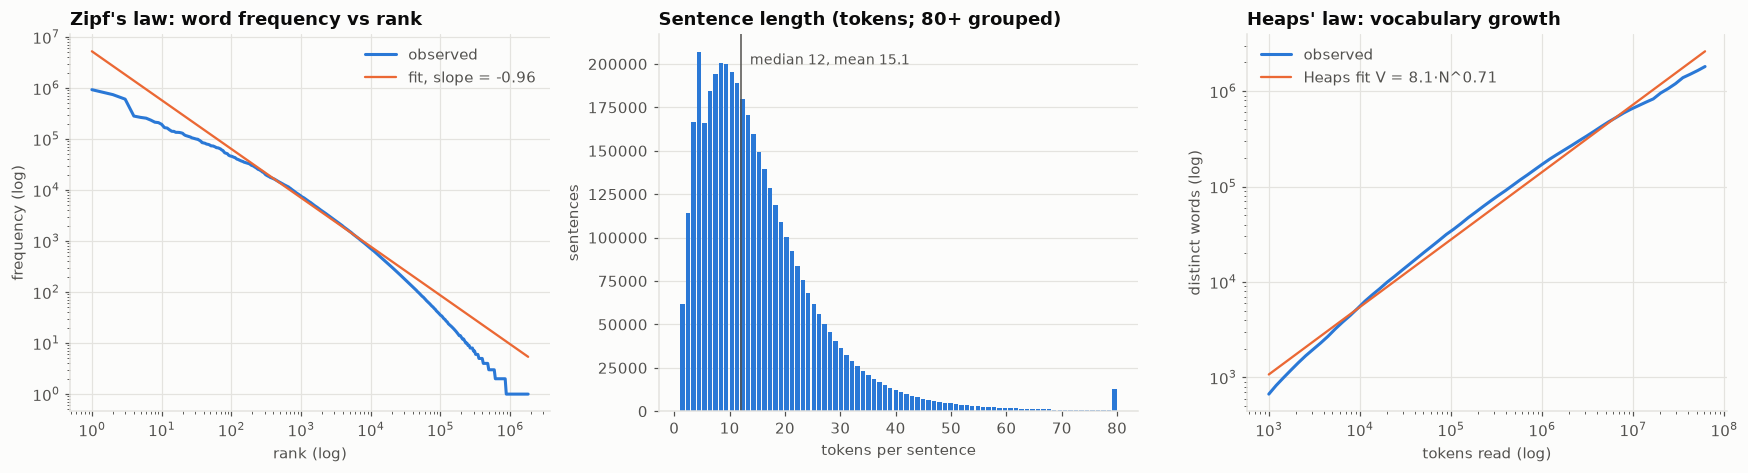

In [7]:
freq = np.bincount(clean.ids, minlength=len(clean.vocab)); freq[[BOS, EOS, UNK]] = 0
f, r, slope, icpt = an.zipf_fit(freq)
Ns, Vs, K, beta = an.heaps_curve(clean.ids)
lens = clean.sentence_lengths()

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
step = np.unique(np.logspace(0, np.log10(len(f)), 400).astype(int)) - 1
ax[0].loglog(r[step], f[step], color=viz.SERIES[0], label="observed")
ax[0].loglog(r[step], 10 ** icpt * r[step] ** slope, color=viz.SERIES[1], lw=1.5, label=f"fit, slope = {slope:.2f}")
ax[0].set(title="Zipf's law: word frequency vs rank", xlabel="rank (log)", ylabel="frequency (log)"); ax[0].legend()

ax[1].hist(np.clip(lens, 1, 80), bins=80, color=viz.SERIES[0], rwidth=0.8)
ax[1].axvline(np.median(lens), color=viz.INK_2, lw=1)
ax[1].annotate(f"median {np.median(lens):.0f}, mean {lens.mean():.1f}", (np.median(lens), ax[1].get_ylim()[1] * 0.92),
               xytext=(6, 0), textcoords="offset points", color=viz.INK_2, fontsize=9)
ax[1].set(title="Sentence length (tokens; 80+ grouped)", xlabel="tokens per sentence", ylabel="sentences"); ax[1].grid(axis="x", visible=False)

ax[2].loglog(Ns, Vs, color=viz.SERIES[0], label="observed")
ax[2].loglog(Ns, K * Ns ** beta, color=viz.SERIES[1], lw=1.5, label=f"Heaps fit V = {K:.1f}·N^{beta:.2f}")
ax[2].set(title="Heaps' law: vocabulary growth", xlabel="tokens read (log)", ylabel="distinct words (log)"); ax[2].legend()
fig.tight_layout(); viz.save(fig, "1_1_corpus_statistics.png"); plt.show()

**Observations (1.1)**

* **Size.** 424M characters (1.06 GB: an Ethiopic character takes 3 bytes in UTF-8). After preprocessing:
  76.7M tokens in 5.09M sentences. De-duplication removed 1.0M repeated sentences (14.8M tokens, **19%** of the
  corpus; mostly re-published articles and boilerplate), leaving **61.9M tokens, 4.09M sentences and 1.81M word
  types**.
* **Normalisation matters.** Merging homophone letters and numbers collapsed 189,702 spelling variants (9.5% of the
  raw types). For example, ሀገር / ሃገር / ሐገር all become one word.
* **A very large vocabulary.** The type/token ratio is 0.029, and **52% of all types are hapax legomena** (seen
  exactly once). Amharic is morphologically rich: prepositions, articles, possessives, object markers and
  conjunctions attach to the word (የኢትዮጵያ *of Ethiopia*, በአፍሪካ *in Africa*, ቤቱን *the house (obj.)*).
  One lemma therefore appears in dozens of surface forms, and the 100 most frequent words cover only 18% of the
  text. This is the main source of data sparsity for n-gram models.
* **Zipf and Heaps.** Frequency against rank follows Zipf's law with slope ≈ −0.96 (close to the ideal −1).
  Vocabulary growth follows Heaps' law V ≈ 8.1·N^0.71 and shows no sign of levelling off: every additional
  million tokens still brings new words.
* **Sentences** have median length 12 and mean 15.1 tokens. Word length is 4.1 characters per token (each
  Ethiopic character is a syllable) but 6.0 per type, because rare words are long, inflected forms. A few very
  long "sentences" (up to 15,614 tokens) are text that has no sentence terminators.
* **Corpus artefacts.** Besides the deleted `.` `,` `-` (repaired in step 0), the letter **ኃ never occurs** in
  GPAC. It was evidently lost when the corpus was created, so ኃላፊነት appears as ላፊነት (21,008 times) and
  ኃይለማርያም as ይለማርያም. The models learn these truncated forms.

## 1.2 Creating n-grams (n = 1, 2, 3, 4)

Every sentence is padded with **n−1 start symbols `<s>`** and **one end symbol `</s>`**, so the first word is
predicted from "beginning of sentence" and the model also learns how sentences end. `<s>` is never predicted;
`</s>` is. A sentence with *m* words therefore produces *m + 1* n-grams for every n.

In [8]:
example = preprocess.tokenize("ኢትዮጵያ በአፍሪካ ቀንድ ትገኛለች።")
for n in range(1, 5):
    grams = an.ngrams(example, n)
    print(f"{n}-grams ({len(grams)}):", ["  ".join(g) for g in grams])

1-grams (5): ['ኢትዮጵያ', 'በአፍሪካ', 'ቀንድ', 'ትገኛለች', '</s>']
2-grams (5): ['<s>  ኢትዮጵያ', 'ኢትዮጵያ  በአፍሪካ', 'በአፍሪካ  ቀንድ', 'ቀንድ  ትገኛለች', 'ትገኛለች  </s>']
3-grams (5): ['<s>  <s>  ኢትዮጵያ', '<s>  ኢትዮጵያ  በአፍሪካ', 'ኢትዮጵያ  በአፍሪካ  ቀንድ', 'በአፍሪካ  ቀንድ  ትገኛለች', 'ቀንድ  ትገኛለች  </s>']
4-grams (5): ['<s>  <s>  <s>  ኢትዮጵያ', '<s>  <s>  ኢትዮጵያ  በአፍሪካ', '<s>  ኢትዮጵያ  በአፍሪካ  ቀንድ', 'ኢትዮጵያ  በአፍሪካ  ቀንድ  ትገኛለች', 'በአፍሪካ  ቀንድ  ትገኛለች  </s>']


The same extraction is applied to all 4.1M sentences with numpy. `full` holds the four count tables built from
the whole clean corpus; it is used for the rest of Task 1 and for the Task 4 application.

ready in 2.2s


,n,"n-gram tokens (with <s>,</s>)",distinct n-grams,distinct contexts,singletons,singletons %,max count
0,1,65968416,1810801,1,945786,52.23,4085911
1,2,65968416,23686097,1810801,17739498,74.89,598872
2,3,65968416,44431120,23484966,38287940,86.17,80075
3,4,65968416,52134952,42926034,47187260,90.51,80075


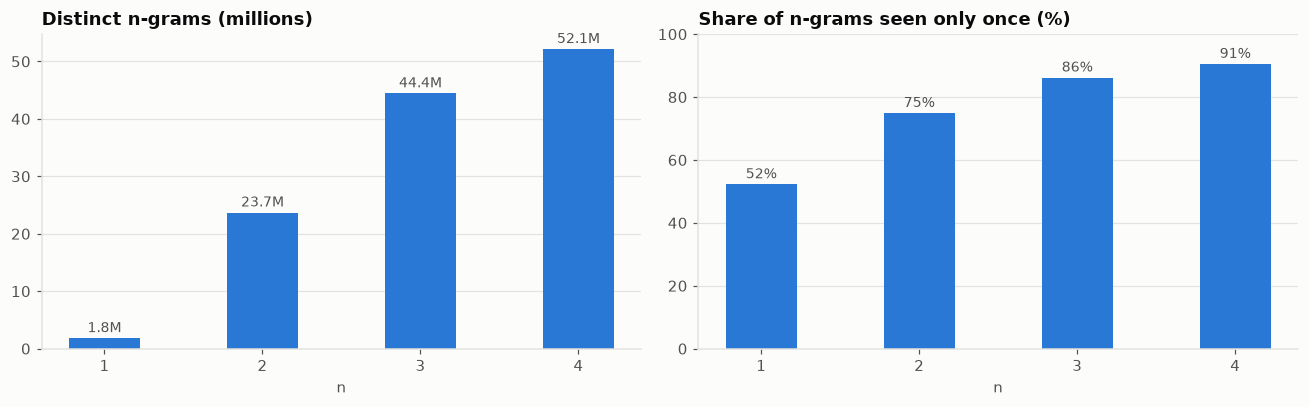

In [9]:
t = time.time()
full = pipeline.full_model(mmap=True)   # trains (~1 min) the first time, then loads from artifacts/
print(f"ready in {time.time() - t:.1f}s")
tsum = an.table_summary(full.tables, clean)
display(tsum)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(tsum["n"], tsum["distinct n-grams"] / 1e6, width=0.45, color=viz.SERIES[0])
for x, y in zip(tsum["n"], tsum["distinct n-grams"] / 1e6):
    ax[0].annotate(f"{y:.1f}M", (x, y), xytext=(0, 4), textcoords="offset points", ha="center", color=viz.INK_2, fontsize=9)
ax[0].set(title="Distinct n-grams (millions)", xlabel="n", xticks=[1, 2, 3, 4]); ax[0].grid(axis="x", visible=False)
ax[1].bar(tsum["n"], tsum["singletons %"], width=0.45, color=viz.SERIES[0])
for x, y in zip(tsum["n"], tsum["singletons %"]):
    ax[1].annotate(f"{y:.0f}%", (x, y), xytext=(0, 4), textcoords="offset points", ha="center", color=viz.INK_2, fontsize=9)
ax[1].set(title="Share of n-grams seen only once (%)", xlabel="n", xticks=[1, 2, 3, 4], ylim=(0, 100)); ax[1].grid(axis="x", visible=False)
fig.tight_layout(); viz.save(fig, "1_2_ngram_counts.png"); plt.show()

In [10]:
rng = np.random.default_rng(7)
s_id = 12345
print("Sentence:", " ".join(clean.sentence(s_id, display=True)), "\n")
for n in range(1, 5):
    t = full.tables[n]
    rows = rng.choice(len(t), 6, replace=False)
    sample = [(an.ngram_string(full.vocab, g), int(c)) for g, c in zip(t.ngram_tokens(rows), t.counts[rows])]
    print(f"random distinct {n}-grams with counts:", sample)

Sentence: ይሄኛው እንደ አዲስ አበባው በሩን ቆልፎ ሱባኤ አልያዘም 

random distinct 1-grams with counts: [('ተከተሉም', 2), ('ያሰባስብኩት', 1), ('መቅደሳትና', 1), ('የተንጠፈጠፈው', 1), ('ያልተደራጁም', 1), ('ዘውገኝት', 1)]
random distinct 2-grams with counts: [('መግለጻቸው አልሸባብም', 1), ('ወር የተገበያየው', 4), ('<s> የተደቀነብን', 2), ('የሰጠሽኝን እህል', 1), ('በሚፈልጓቸው በርካታ', 1), ('በእገዳ ላይ', 2)]
random distinct 3-grams with counts: [('የትግራይ የሚል ነው', 1), ('በመሆኑም መንግሥት እነዚህን', 4), ('ስሜት ጨምድደው ስለያዟት', 1), ('የፕሮግራማቲክ መሰረትን በመያዝ', 1), ('ዳንኤል አሁንም በድጋሚ', 1), ('የኮርፖሬሽኑ ከፍተኛ ላፊዎች', 1)]
random distinct 4-grams with counts: [('ማጠናከርና የልዩ ፍላጎት እንዲሁም', 1), ('ውሏል ቢሉም በተለያዩ ዩንቨርስቲዎች', 1), ('ርምጃ ወስዷል ወዘተ በማለት', 1), ('በጋችን ቶሎ ቢመጣልን ነው', 1), ('ሲረዳ ማንስ ግድ ብሎት', 1), ('ሚኒስቴር በጀትን በተመለከተ የማህበራዊ', 1)]


## 1.3 N-gram probabilities and the 10 most likely n-grams

Two maximum-likelihood probabilities are reported for each n-gram:

* **joint** $P(w_1\ldots w_n) = \dfrac{C(w_1\ldots w_n)}{N_n}$, where $N_n$ is the number of n-gram tokens
  inside sentences (n-grams that touch `<s>`/`</s>` are excluded from these lists);
* **conditional** $P(w_n \mid w_1\ldots w_{n-1}) = \dfrac{C(w_1\ldots w_n)}{C(w_1\ldots w_{n-1}\,\bullet)}$,
  the quantity an n-gram language model actually uses.

Ranking by joint probability is the same as ranking by count.

In [11]:
for n in range(1, 5):
    display(Markdown(f"**Top 10 {n}-grams**"))
    display(an.top_ngrams(full.tables, n, clean, 10).set_index("rank"))

**Top 10 1-grams**

,1-gram,count,P(n-gram),P(w_n | history)
rank,,,,
1,ነው,928991,0.01501,0.01408
2,<NUM>,742808,0.012,0.01126
3,ላይ,605516,0.009785,0.009179
4,ውስጥ,282324,0.004562,0.00428
5,ወደ,265773,0.004295,0.004029
6,እና,256537,0.004146,0.003889
7,ጋር,234877,0.003796,0.00356
8,ነበር,214164,0.003461,0.003246
9,ግን,210024,0.003394,0.003184


**Top 10 2-grams**

,2-gram,count,P(n-gram),P(w_n | history)
rank,,,,
1,<NUM> <NUM>,55369,0.000958,0.07454
2,<NUM> ዓ/ም,47436,0.0008207,0.06386
3,ቀን <NUM>,38157,0.0006602,0.3751
4,ነገር ግን,34785,0.0006019,0.2078
5,<NUM> ቀን,34394,0.0005951,0.0463
6,አዲስ አበባ,26388,0.0004566,0.3594
7,በ <NUM>,26213,0.0004535,0.5693
8,ብቻ ሳይሆን,25412,0.0004397,0.1917
9,ማለት ነው,25023,0.0004329,0.3409


**Top 10 3-grams**

,3-gram,count,P(n-gram),P(w_n | history)
rank,,,,
1,ቀን <NUM> ዓ/ም,29687,0.0005521,0.778
2,<NUM> ቀን <NUM>,28729,0.0005343,0.8353
3,<NUM> <NUM> <NUM>,9638,0.0001792,0.1741
4,<NUM> ሚሊዮን ብር,6177,0.0001149,0.2993
5,ዓ/ም ኢሳት ዜና,5981,0.0001112,0.9858
6,<NUM> ዓ/ም ኢሳት,5699,0.000106,0.1201
7,<NUM> ዓ ም,5177,9.628e-05,0.8104
8,<NUM> ነጥብ <NUM>,5163,9.602e-05,0.7774
9,ተወካዮች ምክር ቤት,4811,8.947e-05,0.9373


**Top 10 4-grams**

,4-gram,count,P(n-gram),P(w_n | history)
rank,,,,
1,<NUM> ቀን <NUM> ዓ/ም,23872,0.0004788,0.8309
2,ቀን <NUM> ዓ/ም ኢሳት,5698,0.0001143,0.1919
3,<NUM> ዓ/ም ኢሳት ዜና,5623,0.0001128,0.9867
4,<NUM> <NUM> <NUM> <NUM>,4953,9.933e-05,0.5139
5,ቀን <NUM> ዓ ም,4033,8.088e-05,0.9373
6,ዓ ም ኢሳት ዜና,3691,7.402e-05,0.9989
7,<NUM> ዓ ም ኢሳት,3643,7.306e-05,0.7037
8,የሕዝብ ተወካዮች ምክር ቤት,2453,4.919e-05,0.9122
9,መጋቢት <NUM> ቀን <NUM>,2263,4.538e-05,0.8809


In [12]:
display(Markdown("**For comparison — top bigrams when sentence boundaries are kept**"))
an.top_ngrams(full.tables, 2, clean, 6, exclude=(UNK,)).set_index("rank")

**For comparison — top bigrams when sentence boundaries are kept**

,2-gram,count,P(n-gram),P(w_n | history)
rank,,,,
1,ነው </s>,598872,0.01036,0.6446
2,ነበር </s>,159685,0.002763,0.7456
3,ናቸው </s>,85838,0.001485,0.7604
4,<s> <NUM>,80075,0.001385,0.0196
5,<s> ይህ,76710,0.001327,0.01877
6,<NUM> <NUM>,55369,0.000958,0.07454


**Observations (1.3)**

* **Unigrams** are dominated by function words: the copula ነው *is*, the postpositions ላይ *on* and ውስጥ *in*,
  ወደ *to*, እና *and*, ጋር *with*, plus the `<NUM>` class. ነው alone is 1.5% of all tokens.
* **Higher orders** mainly show dates and news datelines: ቀን `<NUM>` ዓ/ም (*day N, Ethiopian calendar*),
  `<NUM>` ዓ/ም ኢሳት ዜና (the dateline of ESAT news), `<NUM>` ሚሊዮን ብር (*N million birr*). Institutional
  names follow, e.g. የሕዝብ ተወካዮች ምክር ቤት (*House of People's Representatives*) and የአዲስ አበባ ከተማ
  አስተዳደር (*Addis Ababa City Administration*). GPAC is largely news text.
* **Joint vs conditional probability.** The joint probability of the top item falls as n grows (0.015 for ነው,
  0.00048 for the top 4-gram) because the probability mass is spread over many more possible sequences. The
  conditional probabilities of the top n-grams rise, because long fixed expressions are very predictable:
  P(ቤት | ተወካዮች ምክር) = 0.94, P(ዜና | ዓ/ም ኢሳት) = 0.99.
* **With sentence boundaries kept**, the most frequent bigram is ነው `</s>` (599K), and P(`</s>` | ነው) = 0.64.
  Amharic is verb-final (SOV), so sentences typically end with the copula or a finite verb (ነበር, ናቸው).

## 1.4 Conditional probability of a word given the previous word (bigrams)

$$P(w_i \mid w_{i-1}) = \frac{C(w_{i-1}\,w_i)}{\sum_w C(w_{i-1}\,w)} = \frac{C(w_{i-1}\,w_i)}{C(w_{i-1})}$$

(every word is followed by something — another word or `</s>` — so the denominator equals the unigram count).

In [13]:
big = full.tables[2]

def p_bigram(prev, word):
    # P(word | prev) by maximum likelihood from the bigram table
    a, b = full.encode([preprocess.normalize_token(prev), preprocess.normalize_token(word)])
    c, tot = big.count(np.array([[a]]), np.array([b]))
    return int(c[0]), int(tot[0]), (c[0] / tot[0] if tot[0] else 0.0)

pairs = [("አዲስ", "አበባ"), ("ጠቅላይ", "ሚኒስትር"), ("በአፍሪካ", "ቀንድ"), ("ኢትዮጵያ", "በአፍሪካ"),
         ("የቡና", "ምርት"), ("የኢትዮጵያ", "ህዝብ"), ("ቀንድ", "ትገኛለች"), ("አበባ", "አዲስ"), ("ቡና", "ጠጣ")]
rows = []
for prev, w in pairs:
    c, tot, p = p_bigram(prev, w)
    rows.append({"P(w | prev)": f"P({w} | {prev})", "C(prev w)": c, "C(prev)": tot, "probability": p})
pd.DataFrame(rows)

,P(w | prev),C(prev w),C(prev),probability
0,P(አበባ | አዲስ),26388,73419,0.3594
1,P(ሚኒስትር | ጠቅላይ),16644,34600,0.481
2,P(ቀንድ | በአፍሪካ),691,10935,0.06319
3,P(በአፍሪካ | ኢትዮጵያ),303,83721,0.003619
4,P(ምርት | የቡና),208,3231,0.06438
5,P(ህዝብ | የኢትዮጵያ),9799,93801,0.1045
6,P(ትገኛለች | ቀንድ),0,2324,0
7,P(አዲስ | አበባ),60,76761,0.0007816
8,P(ጠጣ | ቡና),10,8391,0.001192


In [14]:
def next_word_distribution(prev, k=8):
    i = full.encode([preprocess.normalize_token(prev)])[0]
    words, counts = big.continuations([i])
    o = np.argsort(-counts)[:k]
    assert counts.sum() == big.ctx_total[big.lookup_ctx(np.array([i]))[0][0]]   # sums to C(prev)
    return pd.DataFrame({"next": [("</s>" if w == EOS else full.vocab.display[w]) for w in words[o]],
                         "P": counts[o] / counts.sum()})

tables = {w: next_word_distribution(w) for w in ["አዲስ", "ጠቅላይ", "የቡና", "ኢትዮጵያ", "ትገኛለች"]}
display(pd.concat(tables, axis=1))

አዲስ             ጠቅላይ           የቡና         ኢትዮጵያ          ትገኛለች         
   next        P    next       P  next       P  next        P  next        P
0   አበባ   0.3594   ሚኒስትር   0.481   ምርት 0.06438   ውስጥ  0.08295  </s>   0.8707
1   ዘመን  0.05968   ሚኒስትሩ  0.1821    ዋጋ 0.03312    ነገ  0.01685  ብለዋል  0.01168
2   ነገር  0.03118     ፍርድ 0.04633  ግብይት 0.02878    ቡና  0.01018   ያሉት 0.006446
3  አበባን  0.02897     ዓቃቤ 0.04419    ቤት 0.02786    ላይ 0.007167  በማለት 0.006446
4   ዓመት  0.01693   ሚንስትር 0.02841   መገኛ 0.02445  </s> 0.006271    ሲል 0.004029
5   ዓለም  0.01372   ሚኒስቴር 0.01434   ችግኝ 0.02321  በዓለም 0.006056   ብሏል 0.003626
6  አድማስ 0.009085  ሚኒስትሩን 0.01355   ጥራት 0.01795   የጋራ  0.00602    ሲሉ  0.00282
7  ምዕራፍ 0.008131     ግዛት 0.01104   መጠን 0.01578    እና 0.005769    ብሎ  0.00282

**Observations (1.4)**

* **Fixed expressions** get high conditional probability: P(አበባ | አዲስ) = 0.36 (*Addis → Ababa*) and
  P(ሚኒስትር | ጠቅላይ) = 0.48 (*Prime → Minister*). Open choices are much flatter: P(በአፍሪካ | ኢትዮጵያ) = 0.0036.
* **Bigram probabilities are not symmetric:** P(አዲስ | አበባ) = 0.0008, but P(አበባ | አዲስ) = 0.36.
* **The zero-count problem.** P(ትገኛለች | ቀንድ) = 0. *…የአፍሪካ ቀንድ ትገኛለች* (*…is located in the Horn of
  Africa*) is perfectly good Amharic, but this word pair never occurs in 62M tokens. Under MLE, any sentence
  containing it gets probability 0 (see 1.7). This is why smoothing is needed (Task 2).
* **Verb-final syntax:** after the verb ትገኛለች (*she/it is found*), 87% of the probability goes to `</s>`.
* **Spelling variants** (ሚኒስትር / ሚንስትር) and inflections (ሚኒስትሩ *the minister*, ሚኒስትሩን *the minister (obj.)*)
  compete as separate continuations, which spreads the mass thinly.

## 1.5 Removing stop words and recomputing n-gram frequencies

Amharic has no standard stop-word list in common NLP libraries, so `amharic_lm/stopwords.py` defines a curated
list of function words, picked from the most frequent words of GPAC: copulas and auxiliaries (ነው, ነበር,
ናቸው …), pronouns and demonstratives (እሱ, ይህ, እነዚህ …), conjunctions (እና, ግን, ወይም …),
pre/postpositions (ላይ, ውስጥ, ወደ, ጋር …), discourse adverbs (ደግሞ, ብቻ, አሁን …) and verbs of saying used in
reporting (ብሎ, ብለዋል, ይላል …). Single-letter tokens (mostly fragments such as `አ ም` left from `ዓ.ም` after the
dots were stripped from the corpus) and number tokens are removed too. The n-gram tables are then rebuilt from
scratch on the filtered sentences.

In [15]:
sw_mask = stopword_mask(clean.vocab.itos)
print(f"{len(STOPWORDS)} listed stop words; {sw_mask.sum():,} vocabulary entries flagged "
      f"(with single-letter and number tokens)")
print("sample:", " ".join(sorted(STOPWORDS)[:40]), "...")
filtered = clean.filter_tokens(sw_mask)
print(f"stop-word tokens = {sw_mask[clean.ids].mean():.1%} of the corpus; "
      f"{filtered.n_tokens:,} tokens remain in {filtered.n_sentences:,} sentences")

t = time.time()
sw_tables = {n: NGramTable.build(filtered.ids, filtered.offsets, n, len(clean.vocab)) for n in range(1, 5)}
print(f"rebuilt 4 tables in {time.time() - t:.0f}s")

241 listed stop words; 12,311 vocabulary entries flagged (with single-letter and number tokens)
sample: ሁሉ ሁሉም ሁሉንም ሆነ ሆነው ሆና ሆኖ ሆኖም ለ ለምን ለእኔ ለእኛ ለዚህ ለዚያ ሊሆን ላይ ሌላ ሌላው ሌሎች ሌሎችም ልክ መሆኑ መሆኑን መሆናቸውን መሆን መቼ መካከል ማለት ማን ማንም ማድረግ ምን ምንም ምክንያቱም ራሱ ራሳቸው ሲሆን ሲሉ ሲል ሳይሆን ...


stop-word tokens = 18.6% of the corpus; 50,381,993 tokens remain in 4,062,557 sentences


rebuilt 4 tables in 23s


In [16]:
for n in range(1, 5):
    before = an.top_ngrams(full.tables, n, clean, 10)[[f"{n}-gram", "count"]]
    after = an.top_ngrams(sw_tables, n, filtered, 10)[[f"{n}-gram", "count", "P(n-gram)"]]
    display(Markdown(f"**Top 10 {n}-grams — before vs after stop-word removal**"))
    display(pd.concat({"before": before, "after": after}, axis=1).set_index(pd.RangeIndex(1, 11, name="rank")))

**Top 10 1-grams — before vs after stop-word removal**

before          after                  
     1-gram   count 1-gram   count P(n-gram)
rank                                        
1        ነው  928991     ጊዜ  194532  0.003861
2     <NUM>  742808    ነገር  167390  0.003322
3        ላይ  605516     አቶ  141343  0.002805
4       ውስጥ  282324     ቤት  135411  0.002688
5        ወደ  265773  መንግሥት  135385  0.002687
6        እና  256537     ሥራ  129792  0.002576
7        ጋር  234877     ሰው  121992  0.002421
8       ነበር  214164    ሰዎች  111187  0.002207
9        ግን  210024     ቀን  101729  0.002019
10       ጊዜ  194532    ዓመት  100963  0.002004

**Top 10 2-grams — before vs after stop-word removal**

before              after                 
           2-gram  count      2-gram  count P(n-gram)
rank                                                 
1     <NUM> <NUM>  55369     አዲስ አበባ  26394 0.0005698
2       <NUM> ዓ/ም  47436      ምክር ቤት  20131 0.0004346
3        ቀን <NUM>  38157    በአዲስ አበባ  20116 0.0004343
4          ነገር ግን  34785     ዓለም አቀፍ  17576 0.0003795
5        <NUM> ቀን  34394  ጠቅላይ ሚኒስትር  16644 0.0003593
6         አዲስ አበባ  26388    የአዲስ አበባ  16475 0.0003557
7         በ <NUM>  26213    በአሁኑ ወቅት  15606 0.0003369
8         ብቻ ሳይሆን  25412      ፍርድ ቤት  14619 0.0003156
9          ማለት ነው  25023     ሚሊዮን ብር  13577 0.0002931
10     <NUM> ሚሊዮን  20640   ቤተ ክርስቲያን  13527  0.000292

**Top 10 3-grams — before vs after stop-word removal**

before                        after                
                 3-gram  count                3-gram count P(n-gram)
rank                                                                
1          ቀን <NUM> ዓ/ም  29687             ቀን ኢሳት ዜና  9678 0.0002284
2        <NUM> ቀን <NUM>  28729          ተወካዮች ምክር ቤት  4812 0.0001135
3     <NUM> <NUM> <NUM>   9638          በዓለም አቀፍ ደረጃ  4285 0.0001011
4         <NUM> ሚሊዮን ብር   6177          የአዲስ አበባ ከተማ  4112 9.703e-05
5            ዓ/ም ኢሳት ዜና   5981          በአዲስ አበባ ከተማ  3411 8.049e-05
6         <NUM> ዓ/ም ኢሳት   5699        አበባ ከተማ አስተዳደር  3328 7.853e-05
7             <NUM> ዓ ም   5177  የዕድገትና ትራንስፎርሜሽን ዕቅድ  3131 7.388e-05
8       <NUM> ነጥብ <NUM>   5163    የተባበሩት መንግሥታት ድርጅት  2813 6.638e-05
9          ተወካዮች ምክር ቤት   4811           ከቅርብ ጊዜ ወዲህ  2775 6.548e-05
10        <NUM> ቢሊዮን ብር   4617        የሕዝብ ተወካዮች ምክር  2690 6.347e-05

**Top 10 4-grams — before vs after stop-word removal**

before                          after                
                       4-gram  count                  4-gram count P(n-gram)
rank                                                                        
1          <NUM> ቀን <NUM> ዓ/ም  23872       የሕዝብ ተወካዮች ምክር ቤት  2454 6.350e-05
2            ቀን <NUM> ዓ/ም ኢሳት   5698     የአዲስ አበባ ከተማ አስተዳደር  2186 5.656e-05
3            <NUM> ዓ/ም ኢሳት ዜና   5623   ኦርቶዶክስ ተዋሕዶ ቤተ ክርስቲያን  2052 5.310e-05
4     <NUM> <NUM> <NUM> <NUM>   4953   የኢትዮጵያ ኦርቶዶክስ ተዋሕዶ ቤተ  1527 3.951e-05
5                ቀን <NUM> ዓ ም   4033     ጠቅላይ ሚኒስትር አብይ አህመድ  1497 3.874e-05
6                  ዓ ም ኢሳት ዜና   3691      ጠቅላይ ሚኒስትር መለስ ዜናዊ  1132 2.929e-05
7               <NUM> ዓ ም ኢሳት   3643      ሚኒስትር አብይ አህመድ ዶ/ር  1129 2.921e-05
8           የሕዝብ ተወካዮች ምክር ቤት   2453       ለሕዝብ ተወካዮች ምክር ቤት  1014 2.624e-05
9         መጋቢት <NUM> ቀን <NUM>   2263     ጠቅላይ ሚኒስትር ዐቢይ አህመድ   956 2.474e-05
10        የአዲስ አበባ ከተማ አስተዳደር   2186  ጠቅላይ ሚኒስትር ይለማርያም ደሳለኝ   944 2.443e-05

**Observations (1.5)**

* The curated list (241 words, plus single letters and numbers) removes **18.6% of all tokens**.
* After removal, the top **unigrams** are content words: ጊዜ *time*, ነገር *thing*, አቶ *Mr.*, ቤት *house*,
  መንግሥት *government*, ሥራ *work*, ሰው *person*.
* **Bigrams** become collocations and named entities: አዲስ አበባ, ምክር ቤት *council*, ዓለም አቀፍ *international*,
  ጠቅላይ ሚኒስትር *prime minister*, ፍርድ ቤት *court*, ቤተ ክርስቲያን *church*.
* **Trigrams and 4-grams** become institutions and people: የሕዝብ ተወካዮች ምክር ቤት, ኦርቶዶክስ ተዋሕዶ ቤተ
  ክርስቲያን, ጠቅላይ ሚኒስትር አብይ አህመድ / መለስ ዜናዊ / (ኃ)ይለማርያም ደሳለኝ (with the missing ኃ noted in 1.1),
  and the policy name የዕድገትና ትራንስፎርሜሽን ዕቅድ (*Growth and Transformation Plan*).
* **Caveat:** removing words joins tokens that were not adjacent (ቀን ኢሳት ዜና comes from
  ቀን `<NUM>` ዓ/ም ኢሳት ዜና). The filtered n-grams are good for keyword and topic analysis, but they are not
  real word sequences and should not be used for language modelling.

## 1.6 Word clouds before and after stop-word removal

The 150 most frequent n-grams of each order (n-grams touching sentence boundaries excluded). Text size and
colour (light → dark blue) both encode frequency. Rendered with the Noto Sans Ethiopic font.

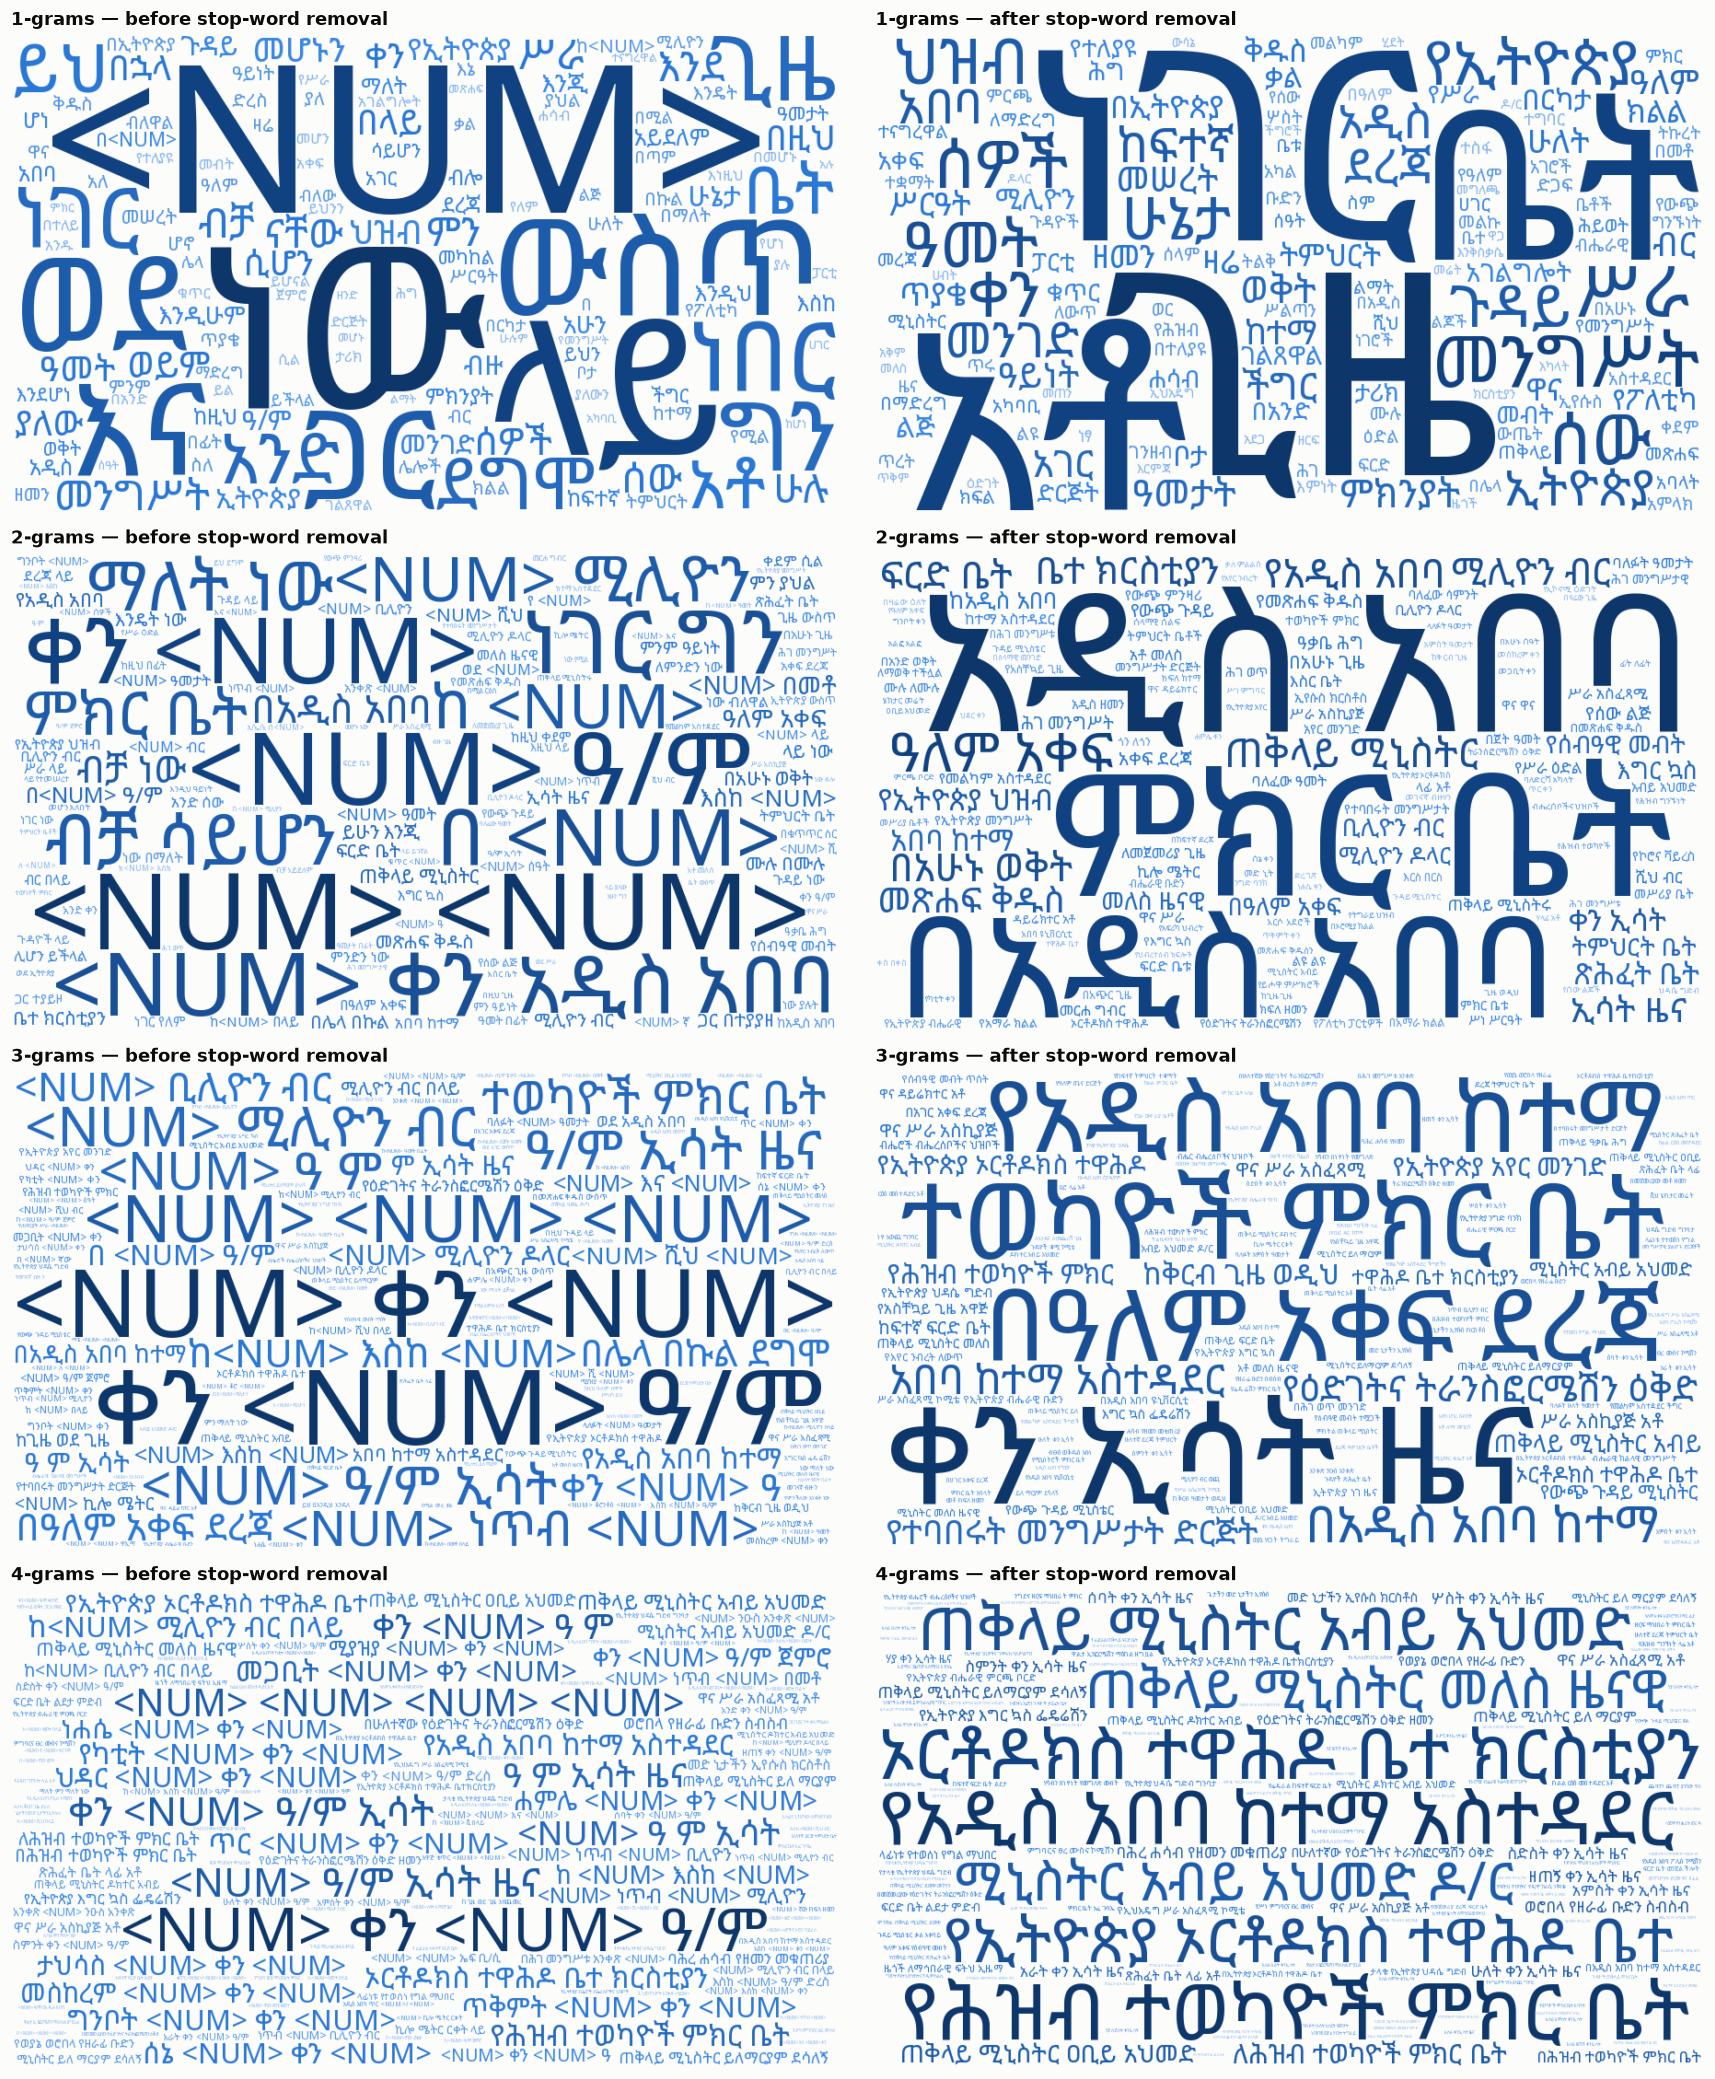

In [17]:
fig, axes = plt.subplots(4, 2, figsize=(16, 19))
for i, n in enumerate(range(1, 5)):
    for j, (tabs, label) in enumerate([(full.tables, "before"), (sw_tables, "after")]):
        freqs = an.ngram_frequencies(tabs, n, clean.vocab, 150)
        viz.wordcloud(freqs, axes[i, j], f"{n}-grams — {label} stop-word removal")
fig.tight_layout(); viz.save(fig, "1_6_wordclouds.png"); plt.show()

**Observations (1.6)**

* **Before** stop-word removal, the clouds are dominated by `<NUM>`, function words (ነው, ላይ, ውስጥ, ወደ) and
  date patterns. They describe Amharic grammar and news formatting more than content.
* **After** removal, the topics of GPAC show up: government and politics (መንግሥት, ጠቅላይ ሚኒስትር, ምክር ቤት,
  የፖለቲካ), the capital (አዲስ አበባ), religion (ቤተ ክርስቲያን, ኦርቶዶክስ ተዋሕዶ, መጽሐፍ ቅዱስ), the economy
  (ሚሊዮን ብር) and international affairs (ዓለም አቀፍ).
* As n grows, the frequency distribution becomes flatter (fewer dominant items), so the clouds look more uniform.
  A few long, highly repeated names and datelines stand out.

In [18]:
del sw_tables, filtered   # free memory

## 1.7 Probability of a sentence

With the chain rule and the Markov assumption, for an n-gram model

$$P(w_1 \ldots w_m) \approx \prod_{i=1}^{m+1} P(w_i \mid w_{i-n+1} \ldots w_{i-1}), \qquad w_{m+1} = \texttt{</s>}$$

computed in log space to avoid underflow. Each sentence is scored with the unsmoothed **MLE** estimate
(as the question asks) and with **interpolated Kneser-Ney** smoothing (Task 2), which never gives
probability 0.

In [19]:
s = "ኢትዮጵያ በአፍሪካ ቀንድ ትገኛለች።"
print("tokens:", preprocess.tokenize(s))
for n in (2, 3):
    steps, summ = an.sentence_report(full, s, n, "mle")
    display(Markdown(f"**{n}-gram MLE, step by step** — P(sentence) = {summ['P']:.3e}, "
                     f"log10 P = {summ['log10 P']:.3f}, per-word perplexity = {summ['perplexity']:.1f}"))
    display(steps)

tokens: ['ኢትዮጵያ', 'በአፍሪካ', 'ቀንድ', 'ትገኛለች']


**2-gram MLE, step by step** — P(sentence) = 0.000e+00, log10 P = -inf, per-word perplexity = inf

,history,word,P(word | history)
0,<s>,ኢትዮጵያ,0.004011
1,ኢትዮጵያ,በአፍሪካ,0.003619
2,በአፍሪካ,ቀንድ,0.06319
3,ቀንድ,ትገኛለች,0
4,ትገኛለች,</s>,0.8707


**3-gram MLE, step by step** — P(sentence) = 0.000e+00, log10 P = -inf, per-word perplexity = inf

,history,word,P(word | history)
0,<s> <s>,ኢትዮጵያ,0.004011
1,<s> ኢትዮጵያ,በአፍሪካ,0.007322
2,ኢትዮጵያ በአፍሪካ,ቀንድ,0.1617
3,በአፍሪካ ቀንድ,ትገኛለች,0
4,ቀንድ ትገኛለች,</s>,0


In [20]:
rows = []
for n in range(1, 5):
    for m in ("mle", "kn"):
        _, summ = an.sentence_report(full, s, n, m)
        rows.append({"n": n, "estimator": m.upper(), **summ})
pd.DataFrame(rows).pivot(index="n", columns="estimator")

log10 P                P           perplexity      
estimator      KN    MLE        KN       MLE         KN   MLE
n                                                            
1          -16.76 -16.76 1.727e-17 1.727e-17      2,252 2,252
2          -11.28   -inf 5.243e-12         0      180.3   inf
3          -10.77   -inf 1.690e-11         0      142.7   inf
4          -10.73   -inf 1.880e-11         0      139.7   inf

In [21]:
more = ["ኢትዮጵያ በአፍሪካ ቀንድ ትገኛለች።",
        "አዲስ አበባ የኢትዮጵያ ዋና ከተማ ናት።",
        "የኢትዮጵያ ህዝብ ቁጥር ከመቶ ሚሊዮን በላይ ነው።",
        "ቡና የኢትዮጵያ ዋነኛ የውጭ ምንዛሪ ምንጭ ነው።",
        "ትገኛለች ቀንድ በአፍሪካ ኢትዮጵያ።",            # same words, scrambled order
        "ሰማዩ አረንጓዴ ቡና በፍጥነት ይዘምራል።"]           # grammatical-looking nonsense
an.sentence_probability_table(full, more)

,sentence,estimator,1-gram P,2-gram P,3-gram P,4-gram P
0,ኢትዮጵያ በአፍሪካ ቀንድ ትገኛለች።,MLE,1.727e-17,0,0,0
1,ኢትዮጵያ በአፍሪካ ቀንድ ትገኛለች።,KN,1.727e-17,5.243e-12,1.690e-11,1.880e-11
2,አዲስ አበባ የኢትዮጵያ ዋና ከተማ ናት።,MLE,1.957e-20,2.535e-13,2.337e-09,3.278e-08
3,አዲስ አበባ የኢትዮጵያ ዋና ከተማ ናት።,KN,1.957e-20,2.794e-13,2.896e-09,3.717e-08
4,የኢትዮጵያ ህዝብ ቁጥር ከመቶ ሚሊዮን በላይ ነው።,MLE,6.378e-23,2.585e-14,0,0
5,የኢትዮጵያ ህዝብ ቁጥር ከመቶ ሚሊዮን በላይ ነው።,KN,6.378e-23,2.632e-14,9.068e-14,6.508e-14
6,ቡና የኢትዮጵያ ዋነኛ የውጭ ምንዛሪ ምንጭ ነው።,MLE,1.854e-25,3.723e-18,2.858e-13,0
7,ቡና የኢትዮጵያ ዋነኛ የውጭ ምንዛሪ ምንጭ ነው።,KN,1.854e-25,4.236e-18,9.741e-15,5.586e-12
8,ትገኛለች ቀንድ በአፍሪካ ኢትዮጵያ።,MLE,1.727e-17,0,0,0
9,ትገኛለች ቀንድ በአፍሪካ ኢትዮጵያ።,KN,1.727e-17,2.131e-22,1.634e-22,1.861e-22


**Observations (1.7)**

* The sentence has 4 words, so the model makes 5 predictions, including `</s>`.
* **Unigram:** P = 1.7×10⁻¹⁷. This is just the product of word frequencies, so word order is ignored.
* **Bigram and higher MLE: P = 0.** The pair ቀንድ ትገኛለች never occurs in the corpus. The other factors are
  reasonable (e.g. P(`</s>` | ትገኛለች) = 0.87), but a single zero wipes out the product. The trigram and 4-gram
  have even more unseen events.
* **Kneser-Ney** gives 5.2×10⁻¹² (bigram), 1.7×10⁻¹¹ (trigram) and 1.9×10⁻¹¹ (4-gram). The per-word
  perplexity of the sentence falls from 2,252 (unigram) to 180 → 143 → 140: more context makes each word more
  predictable.
* **Other sentences.** *አዲስ አበባ የኢትዮጵያ ዋና ከተማ ናት* (*Addis Ababa is the capital of Ethiopia*) has a
  non-zero MLE probability at every order (3.3×10⁻⁸ with the 4-gram), because all of its 4-grams occur in the
  corpus. The **scrambled** sentence has exactly the same unigram probability, but its KN bigram probability
  (2.1×10⁻²²) is **10 orders of magnitude lower** than the correct order (5.2×10⁻¹²). The grammatical-looking
  **nonsense** sentence stays around 10⁻²⁵–10⁻²⁴ at every order.
* Sentence probabilities shrink with length (more factors to multiply), so compare sentences of different
  length by per-word perplexity, not by raw probability.

## 1.8 Generating random sentences

Start from `<s>`…`<s>`, repeatedly **sample** the next word from the MLE distribution
$P(w \mid \text{last } n-1 \text{ words})$, and stop at `</s>` (or after 25 words). Same random seed for every n.

In [22]:
for n in range(1, 5):
    rng = np.random.default_rng(100 + n)
    print(f"── {n}-gram model " + "─" * 60)
    for _ in range(5):
        print("  •", " ".join(full.words(full.generate(n, rng, 25))) + " ።")
    print()

── 1-gram model ────────────────────────────────────────────────────────────


  • ጥቅም ጃንደረቦች ይሰጠናል ሰፊ አቶ በደመቀ መንግሥታዊ አውጪ በቻይና በሌላ ታውቋል ትጠፋለህ መዘዙ በማይሆን አቶ ስምምነት ነው ተፀፀተው በማሰባሰብ ትምህርት ያንብቡ ከብዙዎቹ የአፍሪካ ውድድሮችን ወደ ።
  • ያመለክታል በሚደረገው ።
  • ጓደኛህ ከምታደርገው የተከበረ ወዴት የምታገናኘን አንቀጽ ማርያም ተፅዕኖ ቅድመ ሁነኛ እየጨመረ መንፈስ ፖለቲከኛ ያለን ።


  • የበለጠ አስተያየት ።
  •  ።

── 2-gram model ────────────────────────────────────────────────────────────
  • መስከረም <NUM> ይሁንና የተሟላ መረጃ እስከተጠናቀረበት ጊዜ እነዚህን ህዝብ የሚኖርበት ይመስለኛል ።
  • <NUM>/<NUM> የፌደራሊዝም መሠረቱ ከመሬት ወረራ ድሆኖ ላይ መንግሥት መፍትሔ ማግኘት ይቻላል ።
  • በአገሪቱ ምሥራቃዊ ምዕራባዊ ሳህራ በረሃ ሲወጣ የፋርማሲው ዘበኛ ከባጥ በላይ ማድረስ መቻሉም ሌላው ምክንያት በግፍ ለተገደሉ ንጽሁን ዜጎችን መንግስትን ከመዳፈር አልተቆጠበም ።
  • እሱ ቸር አባታችንም ሆነ በሌሎች የትብብር ማዕቀፍ በአየር ንብረት አንዱ እናቶችን ቦታ አንዲት ደራሲ እንደሆኑ ባለሙያው ይናገራሉ ።
  • ተደምራችሁ አነቃቂ ፕሮግራም ማስፈጸሚያን የሚመለከቱ ነበሩ በቀጣዩ ዓመት ያህል ሠራተኞች ይገኙበታል ።

── 3-gram model ────────────────────────────────────────────────────────────
  • እሷ ልጅ ሆኖ ሳለ ግለሰቦቹ ግን ችግራቸው የንብረት ባለቤትነት መብቶች ከሚደግፉ ነፃ የኢኮኖሚና የፖለቲካ ማህበረሰብ የጋራ ታሪክ የለውም ።
  • እንደማንኛውም ሠራተኛ እየተከፈላቸው ምርምራቸውን እንዲቀጥሉ የማድረግ ላፊነት አለበት ።
  • ለይቶ ትቶት ሌሎቹን ይዞ መጣ ።
  • <NUM> መናው እንደ ድንብላል ዘር ነበር ።
  • ራሔል ወጣቶች ጎበዞች የመፍጠር ችሎታ እና ላፊነትን እንደመዘንጋት የሚቆጠር እና ሌላው ቢቀር ለትውልድ የሚተርፍ ገንዘብ አታገኝበትም ።

── 4-gram model ────────────────────────────────────────────────────────────
  • የውድድሩ ምዝገባና ፈተና ነሐሴ <NUM>

In [23]:
corpus_h = sentence_hashes(clean)
gen = an.generation_report(full, corpus_h, n_samples=300, max_len=30)
gen

,n,samples,mean length,hit max length %,4-grams seen in corpus %,verbatim corpus sentence %
0,1,284,14.2,17.25,6.139,1.056
1,2,300,13.22,10.33,14.88,4.667
2,3,300,13.08,9.333,66.01,12
3,4,300,13.37,8,99.47,41.33


**What happens as n increases (1.8)**

* **Unigram:** word salad. Words appear in proportion to their frequency, with no syntax at all. Length is
  uncontrolled: `</s>` is sampled about once every 16 words, so 17% of samples hit the 30-word cap and some
  stop immediately (an empty sentence).
* **Bigram:** neighbouring words fit together (*መንግሥት መፍትሔ ማግኘት ይቻላል*, *the government can find a
  solution*), but there is no global plan. The topic drifts every few words, and long sentences are ungrammatical
  as a whole.
* **Trigram:** mostly grammatical clauses with verb-final structure; short sentences are often perfect:
  *ለይቶ ትቶት ሌሎቹን ይዞ መጣ* (*he left it aside and came with the others*). Longer ones still wander between
  topics.
* **4-gram:** fluent, natural-looking sentences, but largely **copied**. 99.5% of the generated 4-grams exist
  in the corpus, and **41% of the sentences are verbatim corpus sentences** (1% → 5% → 12% → 41% from n = 1 to 4).
  90% of the 4-grams are singletons, so once the history is a rare trigram there is usually only one way to
  continue, and the model replays its training data.
* **Trade-off:** larger n gives more fluency but less novelty. With fixed data, high-order models overfit
  (sparsity). That is what smoothing/back-off (Task 2), larger corpora, or models that generalise across similar
  words (neural LMs) address.

<a id="task2"></a>
# Task 2 — Intrinsic evaluation: perplexity

**Setup.** The clean corpus is split 90 / 5 / 5 % into *train / dev / test*. The split is by **blocks of 200
consecutive sentences** (seed 42), so sentences of one article mostly stay on the same side. A fresh set of
models (n = 1…4) is trained on the training part only. Words seen only once in training are mapped to `<UNK>`,
which gives a closed vocabulary and lets unknown test words get a probability.

**Metric.** $PP = \exp\!\big(-\tfrac{1}{N}\sum_{i=1}^{N}\ln P(w_i \mid h_i)\big)$ over all *N* test tokens,
including `</s>`. Lower is better; $\log_2 PP$ is the cross-entropy in bits per word.

**Estimators compared**

* **MLE** — no smoothing; any unseen n-gram has probability 0, which makes the perplexity infinite;
* **Laplace** (add-1): $\frac{C(h,w)+1}{C(h)+|V|}$;
* **Add-k**: $\frac{C(h,w)+k}{C(h)+k|V|}$, with *k* chosen on the dev set from 1 … 0.0001;
* **Interpolated Kneser-Ney**: absolute discounting ($D = n_1/(n_1+2n_2)$ per order) interpolated with
  lower-order *continuation* probabilities; the standard strong baseline for n-gram models.

In [24]:
train, dev, test = pipeline.split_corpora(clean)
tm = pipeline.train_model(mmap=True)
split = pd.DataFrame({"sentences": [c.n_sentences for c in (train, dev, test)],
                      "tokens": [c.n_tokens for c in (train, dev, test)],
                      "OOV rate (-> <UNK>)": ["-", f"{ev.oov_rate(tm, dev):.2%}", f"{ev.oov_rate(tm, test):.2%}"]},
                     index=["train", "dev", "test"])
print(f"model vocabulary |V| = {tm.vocab_size:,} (training words seen >= 2 times + </s> + <UNK>)")
display(split)
display(Markdown("**How much of the test set has been seen in training?**"))
ev.ngram_coverage(tm, test)

model vocabulary |V| = 810,853 (training words seen >= 2 times + </s> + <UNK>)


,sentences,tokens,OOV rate (-> <UNK>)
train,3677311,55690918,-
dev,204200,3111799,2.58%
test,204400,3079788,2.60%


**How much of the test set has been seen in training?**

,n,test_events,ngram_seen_%,context_seen_%
0,1,3284188,100,100
1,2,3284188,75.52,100
2,3,3284188,42.04,75.57
3,4,3284188,27.69,43.57


In [25]:
t = time.time()
ppl = ev.perplexity_table(tm, dev, test)
print(f"({time.time() - t:.0f}s)")
pt = ppl.pivot(index="method", columns="n", values="perplexity")
pt = pt.loc[["MLE (unsmoothed)", "Laplace (add-1)", "Add-k (k tuned on dev)", "Interpolated Kneser-Ney"]]
display(Markdown("**Test-set perplexity**"))
display(pt)
display(Markdown("**Details** (MLE: share of test tokens with probability 0, and perplexity over the remaining tokens only; "
                 "k = add-k constant chosen on the dev set)"))
ppl.assign(k=ppl["k"].map(lambda v: "" if pd.isna(v) else f"{v:g}"))

  n=1 done (1.1s)


  n=2 done (3.5s)


  n=3 done (5.9s)


  n=4 done (6.9s)
(17s)


**Test-set perplexity**

n,1,2,3,4
method,,,,
MLE (unsmoothed),"10,609",inf,inf,inf
Laplace (add-1),"10,642","41,202","263,659","411,381"
Add-k (k tuned on dev),"10,609","3,014","20,987","66,596"
Interpolated Kneser-Ney,"10,609","1,264",789.1,704.5


**Details** (MLE: share of test tokens with probability 0, and perplexity over the remaining tokens only; k = add-k constant chosen on the dev set)

,n,method,perplexity,zero_prob_%,ppl_on_seen_events,k,cross_entropy_bits
0,1,MLE (unsmoothed),"10,609",0,"10,609",,13.37
1,1,Laplace (add-1),"10,642",0,NaN,1,13.38
2,1,Add-k (k tuned on dev),"10,609",0,NaN,1e-06,13.37
3,1,Interpolated Kneser-Ney,"10,609",0,NaN,,13.37
4,2,MLE (unsmoothed),inf,24.48,198,,inf
5,2,Laplace (add-1),"41,202",0,NaN,1,15.33
6,2,Add-k (k tuned on dev),"3,014",0,NaN,0.0003,11.56
7,2,Interpolated Kneser-Ney,"1,264",0,NaN,,10.3
8,3,MLE (unsmoothed),inf,57.96,26.18,,inf
9,3,Laplace (add-1),"263,659",0,NaN,1,18.01


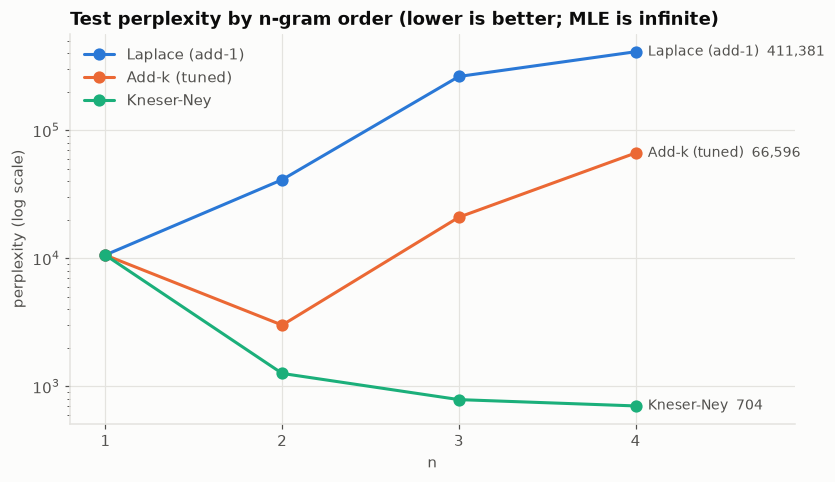

In [26]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ns = [1, 2, 3, 4]
for (name, label), color in zip([("Laplace (add-1)", "Laplace (add-1)"), ("Add-k (k tuned on dev)", "Add-k (tuned)"),
                                 ("Interpolated Kneser-Ney", "Kneser-Ney")], viz.SERIES):
    ys = pt.loc[name, ns].values
    ax.plot(ns, ys, marker="o", color=color, label=label)
    ax.annotate(f"{label}  {ys[-1]:,.0f}", (4, ys[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", color=viz.INK_2, fontsize=9)
ax.set_yscale("log")
ax.set(title="Test perplexity by n-gram order (lower is better; MLE is infinite)",
       xlabel="n", ylabel="perplexity (log scale)", xticks=ns, xlim=(0.8, 4.9))
ax.legend(loc="upper left")
viz.save(fig, "2_perplexity.png"); plt.show()

**Interpretation (Task 2)**

* **Coverage explains everything.** 75.5% of the test bigrams were seen in training, but only 42.0% of the
  trigrams and 27.7% of the 4-grams. For 4-grams, 56% of the *contexts* had never been seen.
* **MLE is unusable:** 24% / 58% / 72% of the test tokens get probability 0 for n = 2/3/4, so the perplexity is
  infinite. Measured only on the events that were seen, it looks deceptively good (198 / 26 / 21). That number
  is meaningless, because the model simply fails on most of the text.
* **Laplace gets worse as n grows** (10.6K → 41K → 264K → 411K). Adding one count to each of the |V| = 810,853
  possible continuations of a context gives almost all the probability to unseen events. The effect is worst at
  high orders, where most contexts were observed only a few times.
* **Add-k** with k tuned on dev (3·10⁻⁴ for bigrams, 3·10⁻⁵ and 3·10⁻⁶ for tri/4-grams) helps the bigram
  (3,014) but still degrades at higher orders. Spreading mass *uniformly* over unseen words is the wrong idea,
  whatever k is.
* **Kneser-Ney is best at every order and improves monotonically:** 10,609 → 1,264 → 789 → **704.5** (13.4 →
  9.5 bits per word). It gives unseen events the probability of a lower-order model, and the lower orders use
  *continuation counts* (how many different words a word follows) instead of raw frequency. The gains shrink
  quickly: −38% from n = 2 to 3, but only −11% from 3 to 4, because most 4-gram contexts are unseen and the
  model backs off anyway.
* The unigram perplexity is the same for all estimators, because `<UNK>` leaves no unseen unigrams.
* The absolute values are much higher than perplexities usually reported for English n-gram models. Amharic's
  rich morphology spreads the probability over a vocabulary of 811K word forms. Perplexities are only comparable
  for the same vocabulary and test set.
* **Conclusion:** the interpolated Kneser-Ney 4-gram is the best model intrinsically; the trigram is almost as
  good and smaller.

<a id="task3"></a>
# Task 3 — Extrinsic evaluation

Extrinsic evaluation puts the language model inside an application and measures how well that application
works. The Task 2 models (trained on *train*, tested on held-out *test* sentences, Kneser-Ney smoothing unless
stated otherwise) are evaluated on three tasks:

| | Task | What the LM does | Metric |
|---|---|---|---|
| **3A** | **Predictive text** (the Task 4 application) | ranks next-word suggestions given the words typed so far | accuracy@1/3/5, MRR, **keystroke savings rate** |
| **3B** | **Context-sensitive spelling correction** | picks the right word among real-word confusions that differ in one vowel order (e.g. ሰበረ / ሰበሩ / ሰባረ) | accuracy |
| **3C** | **Word-order judgement** (as in n-best re-ranking for MT/ASR) | prefers the real sentence over a version with two adjacent words swapped / fully shuffled | pairwise accuracy |

### 3A — Next-word prediction and keystroke savings

In [27]:
t = time.time()
nwp = ev.next_word_prediction(tm, test, n_events=5000)
print(f"5,000 held-out positions; target is <UNK> in {nwp.attrs['target_is_unk_%']:.1f}% of them "
      f"(cannot be predicted)  ({time.time() - t:.0f}s)")
nwp.drop(columns="seconds")

5,000 held-out positions; target is <UNK> in 2.6% of them (cannot be predicted)  (151s)


,n,events,acc@1_%,acc@3_%,acc@5_%,MRR@5
0,1,5000,9.82,12.74,13.62,0.1133
1,2,5000,17.3,23.52,26.54,0.2069
2,3,5000,22.24,29.66,33.1,0.2626
3,4,5000,24.26,31.7,34.58,0.282


**Keystroke savings rate (KSR).** A user types held-out sentences with a 5-slot suggestion bar. Before each
character they check the suggestions, which are filtered by the letters already typed. If the intended word is
shown they tap it: one keystroke, and the space is added automatically. Otherwise they type the next character.
$KSR = 1 - \frac{\text{keystrokes with suggestions}}{\text{keystrokes without}}$, counting one keystroke per
Ethiopic character plus one per space.

In [28]:
t = time.time()
ksr = ev.keystroke_savings(tm, test, n_sentences=200)
print(f"({time.time() - t:.0f}s)")
ksr.drop(columns="seconds")

(80s)


,n,keystrokes_without,keystrokes_with,KSR_%
0,1,12902,8199,36.45
1,2,12902,6912,46.43
2,3,12902,6653,48.43
3,4,12902,6610,48.77


### 3B — Context-sensitive spelling correction (vowel-order confusions)

In [29]:
spell = {m: ev.spelling_correction(tm, test, n_trials=3000, method=m) for m in ("kn", "laplace")}
d = spell["kn"]
print(f"{d['trials'][0]:,} trials, {d.attrs['avg_candidates']:.1f} candidates per trial on average; "
      f"random guessing = {d.attrs['random_baseline_%']:.1f}% accuracy")
iv = tm.vocab.display
for ids, pos, cands in d.attrs["examples"][:4]:
    left, right = " ".join(iv[i] for i in ids[max(0, pos - 4):pos]), " ".join(iv[i] for i in ids[pos + 1:pos + 4])
    print(f"  … {left} [ {iv[cands[0]]} | " + " | ".join(iv[c] for c in cands[1:]) + f" ] {right} …")
pd.concat({"Kneser-Ney": spell["kn"].set_index("n")[["accuracy_%"]],
           "Laplace": spell["laplace"].set_index("n")[["accuracy_%"]]}, axis=1)

3,000 trials, 4.3 candidates per trial on average; random guessing = 29.4% accuracy
  … ፕሮፌሰር መርጋ በቃና ለአንድ [ ጥያቄ | ጥያቂ | ጥየቄ | ጠያቄ | ጥይቄ ] ብቻ መልስ ከሰጡ …
  … ግዜ ዕቅድ አውጥቶ ተግባራዊ [ እያደረገ | እያደረግ | እየደረገ | እያደረጉ ] ነው …
  … ምክንያትም ተጨማሪ ወታደራዊ እርምጃ [ ለመውሰድ | ለመወሰድ | ለመውስድ ] የኢትዮጵያ መንግሥት ተገዶ …
  … ነገ ጥዋት ካልመጡ [ እኔ | እና | እኒ | እን | አኔ | እነ ] ከቀትር በሁዋላ ወዳዲስ …


,Kneser-Ney,Laplace
,accuracy_%,accuracy_%
n,,
1,81.47,81.47
2,90.33,85.6
3,90.47,71.27
4,90.73,81.6


### 3C — Word-order judgement

In [30]:
order_res = {m: ev.word_order_test(tm, test, n_pairs=5000, method=m) for m in ("kn", "laplace")}
pd.concat({"Kneser-Ney": order_res["kn"].set_index("n").drop(columns="pairs"),
           "Laplace": order_res["laplace"].set_index("n").drop(columns="pairs")}, axis=1)

Kneser-Ney                                Laplace                   
  adjacent_swap_acc_% full_shuffle_acc_% adjacent_swap_acc_% full_shuffle_acc_%
n                                                                              
1                  50                 50                  50                 50
2               91.04               99.4               88.48              98.21
3               91.41              99.48               70.22                 93
4               91.32              99.36               59.87              83.45

### Summary: intrinsic vs extrinsic

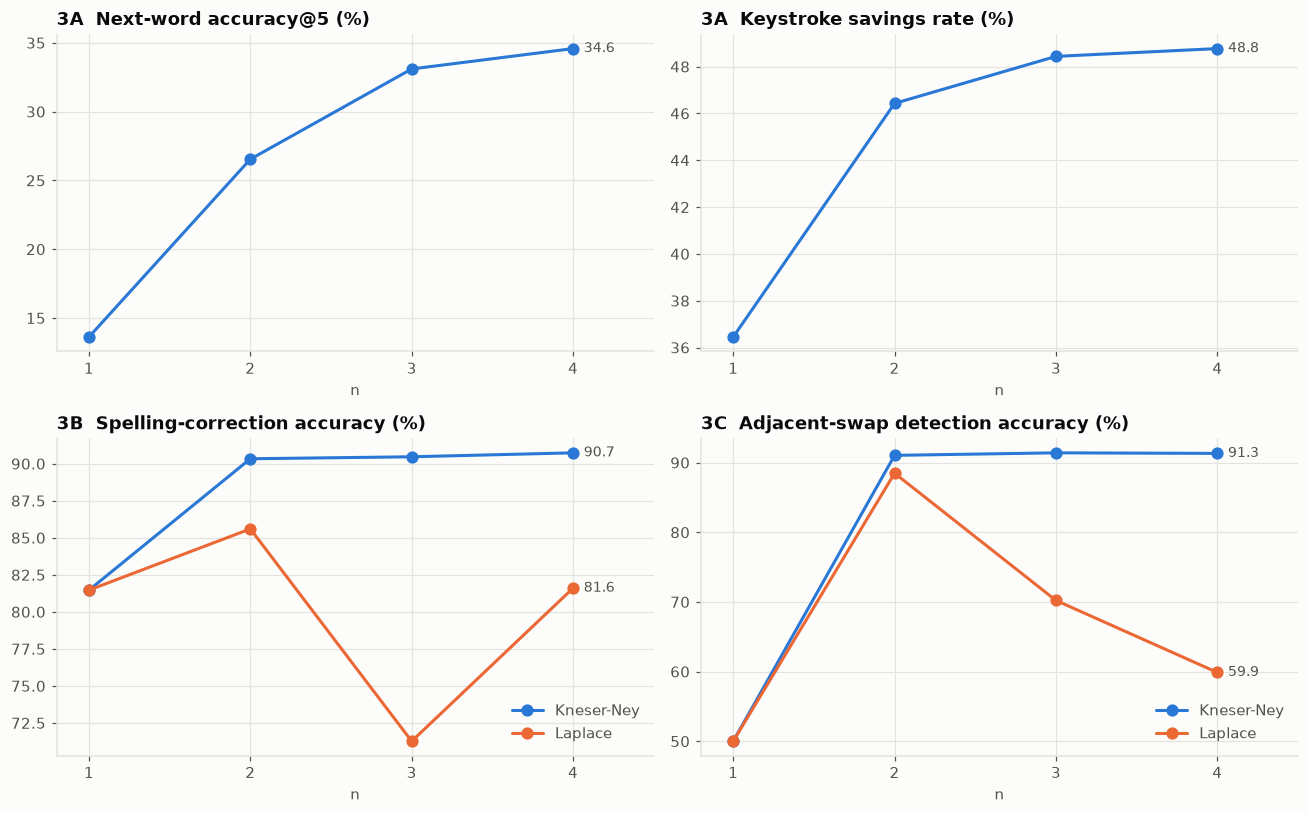

,KN perplexity (Task 2),next-word acc@5 %,KSR %,spelling acc %,swap detection %
n,,,,,
1,"10,609",13.62,36.45,81.47,50
2,"1,264",26.54,46.43,90.33,91.04
3,789.1,33.1,48.43,90.47,91.41
4,704.5,34.58,48.77,90.73,91.32


In [31]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
ns = [1, 2, 3, 4]
panels = [
    (axes[0, 0], "3A  Next-word accuracy@5 (%)", {"Kneser-Ney": nwp["acc@5_%"].values}),
    (axes[0, 1], "3A  Keystroke savings rate (%)", {"Kneser-Ney": ksr["KSR_%"].values}),
    (axes[1, 0], "3B  Spelling-correction accuracy (%)", {"Kneser-Ney": spell["kn"]["accuracy_%"].values,
                                                          "Laplace": spell["laplace"]["accuracy_%"].values}),
    (axes[1, 1], "3C  Adjacent-swap detection accuracy (%)", {"Kneser-Ney": order_res["kn"]["adjacent_swap_acc_%"].values,
                                                              "Laplace": order_res["laplace"]["adjacent_swap_acc_%"].values}),
]
for ax, title, series in panels:
    for (name, ys), color in zip(series.items(), viz.SERIES):
        ax.plot(ns, ys, marker="o", color=color, label=name)
        ax.annotate(f"{ys[-1]:.1f}", (4, ys[-1]), xytext=(7, 0), textcoords="offset points", va="center",
                    color=viz.INK_2, fontsize=9)
    ax.set(title=title, xticks=ns, xlabel="n", xlim=(0.8, 4.5))
    if len(series) > 1:
        ax.legend(loc="lower right")
fig.tight_layout(); viz.save(fig, "3_extrinsic.png"); plt.show()

overview = pd.DataFrame({
    "KN perplexity (Task 2)": pt.loc["Interpolated Kneser-Ney", ns].values,
    "next-word acc@5 %": nwp["acc@5_%"].values, "KSR %": ksr["KSR_%"].values,
    "spelling acc %": spell["kn"]["accuracy_%"].values,
    "swap detection %": order_res["kn"]["adjacent_swap_acc_%"].values}, index=pd.Index(ns, name="n"))
overview

**Interpretation (Task 3)**

* **3A — predictive text.** Top-5 accuracy rises from 13.6% (unigram, which always suggests the most frequent
  words) to 26.5%, 33.1% and **34.6%** for n = 2, 3, 4. Top-1 accuracy rises from 9.8% to 24.3%. In the
  typing simulation, suggestions save **36% → 46% → 48% → 49% of keystrokes**: with a trigram or 4-gram
  model a user types about half as many characters. Even the unigram saves a third, because filtering by the
  typed prefix completes words after a couple of letters. 2.6% of the target words are `<UNK>` and can never be
  suggested.
* **3B — spelling correction.** Choosing the most frequent variant (unigram) is already right 81.5% of the time
  (random guessing: 29.4%). Context lifts this to **~90.5%**, and almost all of the gain comes from the bigram.
  Most vowel-order confusions change a suffix (እያደረገ / እያደረጉ *he / they doing*, ለመውሰድ / ለመወሰድ *to take /
  to be taken*), and the immediate neighbours usually decide such agreement.
* **3C — word order.** A unigram model cannot tell word orders apart (exactly 50%, bag of words). With n ≥ 2,
  Kneser-Ney prefers the real sentence over one with a single adjacent swap 91% of the time, and over a full
  shuffle 99.4% of the time.
* **Smoothing matters downstream too.** Laplace's poor perplexity shows up in the tasks: its word-order accuracy
  falls with n (88.5 → 70.2 → 59.9%) and its spelling accuracy is erratic (71% at n = 3). Laplace gives an unseen
  n-gram after a *frequent* context the probability 1/(C(h)+|V|), which is *smaller* than the 1/|V| given after an
  *unseen* context. It therefore prefers rare or garbled candidates that create unseen contexts. Kneser-Ney does
  not have this problem.
* **Intrinsic vs extrinsic.** Lower perplexity went with better task performance in every task, but the gains
  saturate earlier on the tasks. From n = 3 to 4, perplexity drops 11%, while KSR gains 0.3 points, spelling 0.3
  and word order −0.1. For the application, the **trigram is the sweet spot**: nearly the same quality as the
  4-gram, with a smaller and faster model. Intrinsic evaluation is a cheap proxy; the extrinsic numbers are
  what a user would actually notice.

<a id="task4"></a>
# Task 4 — Amharic predictive text and next-word suggestion system

The engine is `amharic_lm/predictor.py`. Two front-ends use it:

* **Web app** — `python app/server.py`, then open <http://localhost:8000>. Suggestions update as you type.
  Click a suggestion, press **Tab** for the first one, or **Alt+1…5**. A table shows how each candidate was
  scored. It needs only the Python standard library and numpy.
* **Terminal app** — `python app/cli.py`. Type words; enter `1`–`5` to accept a suggestion; end input with `+`
  to complete a half-typed word.

**How a request is processed** (the steps the assignment lists):

1. **Read the input** and keep only the sentence being written (the text after the last `።`, `?`, `!`).
2. **Tokenise and normalise** it exactly like the training corpus (homophones, numbers).
3. **Extract the final one or two words** as the context. The default is the trigram model (last two words),
   and the user can switch to one word (bigram) or three words (4-gram). A short sentence is padded with `<s>`.
   If the text does not end with a space, the last token is a half-typed word and becomes a **prefix filter**.
4. **Retrieve candidates** from the trigram table for the two-word context, then the bigram table for the
   last word, then frequent unigrams. Up to 300 per level, keeping words that match the prefix.
5. **Estimate probabilities** with interpolated Kneser-Ney, $P_{KN}(w \mid w_{i-2} w_{i-1})$. It combines all
   three levels, so a word seen only after the last word still gets a sensible score. The MLE
   $C(h,w)/C(h)$ from the longest context in which the word was seen is shown next to it.
6. **Return the top five.** `</s>` is shown as `።` (end the sentence) and number placeholders are hidden.
7. **The user selects one**: it is inserted, replacing a half-typed word if there is one, and new suggestions
   are computed.

The model behind the app is the `full` model (all 62.9M clean tokens, 1.8M-word vocabulary). It is memory-mapped
from disk, so it starts in about 3 seconds, and a suggestion takes 5–30 ms.

In [32]:
predictor = NextWordPredictor(full, order=3)

def show(text, order=3):
    res = predictor.suggest(text, order=order)
    df = pd.DataFrame(res["suggestions"])[["word", "p", "matched", "count", "p_mle"]]
    df.columns = ["suggestion", "P_KN(w | context)", "seen with", "count", "P_MLE"]
    df.index = range(1, len(df) + 1)
    display(Markdown(f"**Input:** `{text}` → context {res['context']}"
                     + (f", completing **{res['prefix']}…**" if res["prefix"] else "")))
    display(df)

show("ኢትዮጵያ ውስጥ የቡና ")
show("ኢትዮጵያ ውስጥ የቡና ", order=2)

**Input:** `ኢትዮጵያ ውስጥ የቡና ` → context ['ውስጥ', 'የቡና']

,suggestion,P_KN(w | context),seen with,count,P_MLE
1,ፍጆታ,0.1184,trigram,4,0.1481
2,ዋጋ,0.09504,trigram,3,0.1111
3,የወጪ,0.04981,trigram,2,0.07407
4,ፍጆታን,0.0438,trigram,2,0.07407
5,ምርት,0.03847,trigram,1,0.03704


**Input:** `ኢትዮጵያ ውስጥ የቡና ` → context ['የቡና']

,suggestion,P_KN(w | context),seen with,count,P_MLE
1,ምርት,0.06417,bigram,208,0.06438
2,ዋጋ,0.03293,bigram,107,0.03312
3,ግብይት,0.02856,bigram,93,0.02878
4,ቤት,0.0277,bigram,90,0.02786
5,መገኛ,0.02422,bigram,79,0.02445


In [33]:
for text in ["ኢትዮጵያ በአፍሪካ ቀንድ ", "ኢትዮጵያ በአፍሪካ ቀንድ ትገኛለች ", "አዲስ ", "ጠቅላይ ሚኒስትር አብ", "የኢትዮጵያ ህዝብ "]:
    show(text)

**Input:** `ኢትዮጵያ በአፍሪካ ቀንድ ` → context ['በአፍሪካ', 'ቀንድ']

,suggestion,P_KN(w | context),seen with,count,P_MLE
1,አካባቢ,0.107,trigram,73,0.1056
2,ውስጥ,0.04357,trigram,30,0.04342
3,ላይ,0.0425,trigram,28,0.04052
4,ሰላምና,0.03615,trigram,25,0.03618
5,ሰላም,0.02599,trigram,17,0.0246


**Input:** `ኢትዮጵያ በአፍሪካ ቀንድ ትገኛለች ` → context ['ቀንድ', 'ትገኛለች']

,suggestion,P_KN(w | context),seen with,count,P_MLE
1,።,0.6401,bigram,2161,0.8707
2,በማለት,0.01959,bigram,16,0.006446
3,ብለዋል,0.01953,bigram,29,0.01168
4,ያሉት,0.007713,bigram,16,0.006446
5,ያለው,0.006276,bigram,5,0.002015


**Input:** `አዲስ ` → context ['<s>', 'አዲስ']

,suggestion,P_KN(w | context),seen with,count,P_MLE
1,አበባ,0.4968,trigram,6514,0.4855
2,ዘመን,0.2462,trigram,3288,0.2451
3,አበባን,0.02474,trigram,306,0.02281
4,ነገር,0.01475,trigram,174,0.01297
5,አድማስ,0.01337,trigram,173,0.01289


**Input:** `ጠቅላይ ሚኒስትር አብ` → context ['ጠቅላይ', 'ሚኒስትር'], completing **አብ…**

,suggestion,P_KN(w | context),seen with,count,P_MLE
1,አብይ,0.145,trigram,2399,0.1441
2,አብይን,0.00333,trigram,56,0.003365
3,አብደላ,0.003318,trigram,55,0.003304
4,አብይም,0.001251,trigram,21,0.001262
5,አብይና,0.00107,trigram,18,0.001081


**Input:** `የኢትዮጵያ ህዝብ ` → context ['የኢትዮጵያ', 'ህዝብ']

,suggestion,P_KN(w | context),seen with,count,P_MLE
1,አርበኞች,0.04088,trigram,401,0.04092
2,ነው,0.02022,trigram,155,0.01582
3,ሆይ,0.01408,trigram,136,0.01388
4,ጋር,0.01345,trigram,111,0.01133
5,ቁጥር,0.01261,trigram,110,0.01123


**Composing a sentence by selecting suggestions.** This simulates a user who starts with `ኢትዮጵያ` and keeps
choosing, in turn, the 1st, 2nd and 3rd suggestion:

In [34]:
text = "ኢትዮጵያ "
for step, pick in enumerate([0, 1, 0, 2, 0, 0, 1, 0, 0, 0], 1):
    sugg = predictor.suggest(text)["suggestions"]
    choice = sugg[min(pick, len(sugg) - 1)]["word"]
    print(f"{step:>2}. offered: {' | '.join(s['word'] for s in sugg):<55} -> picked '{choice}'")
    text = predictor.apply(text, choice)
    if choice == "።":
        break
print("\nComposed:", text)

 1. offered: ውስጥ | ነገ | ለዘላለም | በክብር | ለዘለዓለም                        -> picked 'ውስጥ'
 2. offered: ያለው | ያለውን | ነው | ያሉ | ግን                               -> picked 'ያለውን'
 3. offered: ነገር | ችግር | ሁኔታ | የሰብዓዊ | መልካም                          -> picked 'ነገር'
 4. offered: ሁሉ | ግን | ነው | እንዴት | ለማወቅ                              -> picked 'ነው'
 5. offered: ። | በማለት | ብለዋል | ምክንያቱም | ማለት                          -> picked '።'

Composed: ኢትዮጵያ ውስጥ ያለውን ነገር ነው። 


**The web app** (`python app/server.py`):

![Amharic next-word suggester](outputs/figures/app_screenshot.png)

**How good is it?** Task 3A measured this exact pipeline on held-out text. See the summary below.

**Assessment (Task 4)**

* **Quality.** With the default trigram context, the system ranks the word the user actually wants among its
  five suggestions about **one time in three** (33.1% in 3A; 22% in first place). It saves **~48% of
  keystrokes** when the user also types prefixes.
* **The example from the assignment.** For *ኢትዮጵያ ውስጥ የቡና* the trigram context (ውስጥ, የቡና) suggests
  ፍጆታ *consumption*, ዋጋ *price*, የወጪ (ንግድ) *export*, ፍጆታን, and ምርት *production*. With the last word only
  (bigram), ምርት comes first (P = 0.064), followed by ዋጋ and ግብይት *trade*. These match the illustrative
  answers in the assignment (ምርት, ንግድ). The two-word context shifts the suggestions towards "coffee *within
  Ethiopia*", i.e. domestic consumption.
* **Other behaviour:** *…የአፍሪካ ቀንድ* → አካባቢ *region* (0.11); after the verb *ትገኛለች* the top suggestion is
  to end the sentence `።` (0.64); *አዲስ* → አበባ (0.50) / ዘመን (0.25); the half-typed *ጠቅላይ ሚኒስትር አብ* is
  completed to አብይ.
* **Limitations.** (1) It reflects the news and politics domain of GPAC. (2) Inflected forms compete for the five
  slots (ፍጆታ / ፍጆታን). (3) Trigram contexts are often sparse (counts of 1–4 above); Kneser-Ney then mixes in
  bigram evidence. (4) It cannot suggest words it has never seen, and it inherits corpus artefacts such as the
  missing ኃ.
* **Possible improvements:** a cache or personal-history model, morpheme-level n-grams (segmenting prefixes
  such as የ-, በ-, ለ-), pruning the singleton 4-grams to shrink the model, and a neural LM for re-ranking the
  top candidates.

# Summary

| | Finding |
|---|---|
| Data | 61.9M clean tokens, 4.09M sentences, 1.81M types; 52% of types are hapax. Amharic morphology means a huge vocabulary and severe sparsity. 19% of the raw corpus was duplicate text, and the letter ኃ is missing from the dump. |
| N-grams | 1.8M / 23.7M / 44.4M / 52.1M distinct 1–4-grams; 75–90% of higher-order n-grams are singletons. Before stop-word removal, top n-grams are function words, numbers and datelines; after removal, they are named entities and institutions. |
| Probabilities | MLE gives probability 0 to most new sentences (e.g. *ኢትዮጵያ በአፍሪካ ቀንድ ትገኛለች* because ቀንድ ትገኛለች is unseen); Kneser-Ney fixes this. |
| Generation | Fluency grows with n, but 4-gram output copies corpus sentences 41% of the time. |
| Task 2 | Test perplexity (KN): 10,609 / 1,264 / 789 / **704.5** for n = 1–4; MLE is infinite; Laplace and add-k get worse with n. |
| Task 3 | Next-word top-5 accuracy 13.6 → 34.6%; keystroke savings 36 → 49%; spelling correction 81.5 → 90.7%; word-order judgement 50 → 91%. Gains flatten after the trigram. |
| Task 4 | A working predictive keyboard (web and terminal) with prefix completion, KN probabilities and explanations; 5–30 ms per suggestion. |

In [35]:
print(f"notebook executed in {(time.time() - T0) / 60:.1f} min")

notebook executed in 5.8 min


### References
* F. B. Gereme, W. Zhu, T. Ayall, D. Alemu. *Combating Fake News in "Low-Resource" Languages: Amharic Fake News
  Detection Accompanied by Resource Crafting.* Information 12(1):20, 2021 — source of the GPAC corpus.
* D. Jurafsky, J. H. Martin. *Speech and Language Processing* (3rd ed. draft), ch. 3 "N-gram Language Models".
* S. F. Chen, J. Goodman. *An Empirical Study of Smoothing Techniques for Language Modeling.* 1999.
* K. Heafield. *KenLM: Faster and Smaller Language Model Queries.* WMT 2011 (adjusted-count convention for `<s>`).